# Sentence Divergence Analysis — TAT German

This notebook runs the full statistical analysis and visualization pipeline
for sentence-level embedding divergence aggregated to person-level metrics.
It loops over three analysis settings (with outliers, without outliers, matched sample)
and produces the same set of plots and statistics for each.

In [1]:
import sys
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

# Make sure project root is on the path
sys.path.insert(0, os.path.abspath('.'))

from services.divergence_analysis_service import analysis_service, load_metadata, build_person_df
from services.plotting_service import plot_setting, plot_cross_setting, plot_advanced
from functions.analysis.statistics import (
    CLINICAL_VARS,
    group_comparison,
    clinical_correlations,
    residualize_ppl,
    nested_regression_models,
    steigers_z,
    compute_roc,
    logistic_cv_auc,
)
from functions.plotting.plots import (
    plot_roc_curves,
    plot_metrics_heatmap,
    plot_raw_vs_residualized,
)

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x74dc2afcca50>>
Traceback (most recent call last):
  File "/zi/home/esra.lenz/CLIP/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


## 1. Configuration

In [ ]:
# Paths
SENTENCE_CSV = "data/03_sentence_divergence/sent_divergence_all.csv"
METADATA_CSV = "data/00_raw_data/Demografics_Speech_FOR2107.csv"
FIGURE_DIR = "figures/divergence"

# Model prefix for column names
MODEL = "divergence"

# Primary divergence variable (main analyses use mean)
PPL_VAR = f"{MODEL}_div_mean"
WC_VAR = f"{MODEL}_total_words"

# Clinical variables
clinical_vars = CLINICAL_VARS
print(f"Clinical variables: {clinical_vars}")

Clinical variables: ['GAF', 'TLI_Impoverished', 'TLI_Disorganization', 'TLI_Non_specific']


## 2. Load data & prepare three analysis settings

In [ ]:
df, settings = analysis_service(
    sentence_csv=SENTENCE_CSV,
    metadata_csv=METADATA_CSV,
    model_name=MODEL,
)

print(f"\nFull dataset: {len(df)} subjects")
print(f"Patients: {(df['is_patient'] == 1).sum()}, Controls: {(df['is_patient'] == 0).sum()}")

High-divergence threshold (90th %ile of controls): 0.2135
Matched sample: 157 patients + 157 controls
  with_outliers: 366 total (189 patients, 177 controls)
  without_outliers: 366 total (189 patients, 177 controls)
  matched: 314 total (157 patients, 157 controls)

Full dataset: 366 subjects
Patients: 189, Controls: 177


In [ ]:
df.head()

,file_id,diagnosis,sex,age,education,comorbidity,GAF,verbal_IQ,TLI_Impoverished,TLI_Disorganization,...,divergence_div_std,divergence_div_p90,divergence_div_p75,divergence_div_cv,divergence_n_sentences,divergence_n_tasks,divergence_total_words,divergence_avg_words,divergence_n_high_div,divergence_prop_high_div
0,0006_3,MDD,male,30,13.0,0,65.0,NaN,0.0,2.25,...,0.031966,0.210995,0.190989,0.188097,122,4,2098,17.196721,9,0.073770
1,0008_3,HC,female,24,13.0,0,82.0,107.0,1.0,0.25,...,0.033860,0.186893,0.179172,0.219694,56,4,842,15.035714,3,0.053571
2,0011_3,MDD,male,52,9.0,1,79.0,94.0,0.0,1.00,...,0.029791,0.210189,0.194333,0.170419,128,4,1587,12.398438,9,0.070312
3,0013_3,MDD,female,44,13.0,0,75.0,118.0,0.0,0.25,...,0.038619,0.204657,0.190267,0.235126,105,4,1701,16.200000,5,0.047619
4,0020_3,MDD,female,26,12.0,1,45.0,104.0,0.0,0.25,...,0.033692,0.213787,0.197836,0.194352,75,4,952,12.693333,8,0.106667


## 3. Loop: Group comparison & clinical correlations for all 3 settings


Setting: with_outliers | PPL variable: divergence_div_mean
Saved: figures/divergence/with_outliers/01_group_boxplot.png


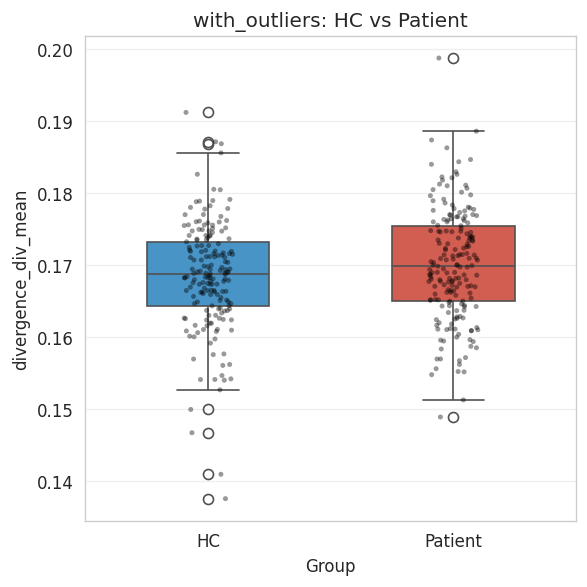


with_outliers — divergence_div_mean:
  Variable: divergence_div_mean
  Control (M±SD): 0.17±0.01
  Patient (M±SD): 0.17±0.01
  Control Median: 0.1687369483548241
  Patient Median: 0.16986176888147986
  t: 2.0338707233170923
  p(t): 0.04268937191522844
  U: 18447.0
  p(MW): 0.08904290196815882
  Cohens d: 0.2127386271487847
  r: -0.10286072997937401

Clinical correlations (with_outliers):
  Clinical Variable         r        p   n
                GAF -0.192409 0.009069 183
   TLI_Impoverished -0.038013 0.614424 178
TLI_Disorganization  0.184477 0.013698 178
   TLI_Non_specific  0.006057 0.936045 178
Saved: figures/divergence/with_outliers/02_clinical_scatter.png


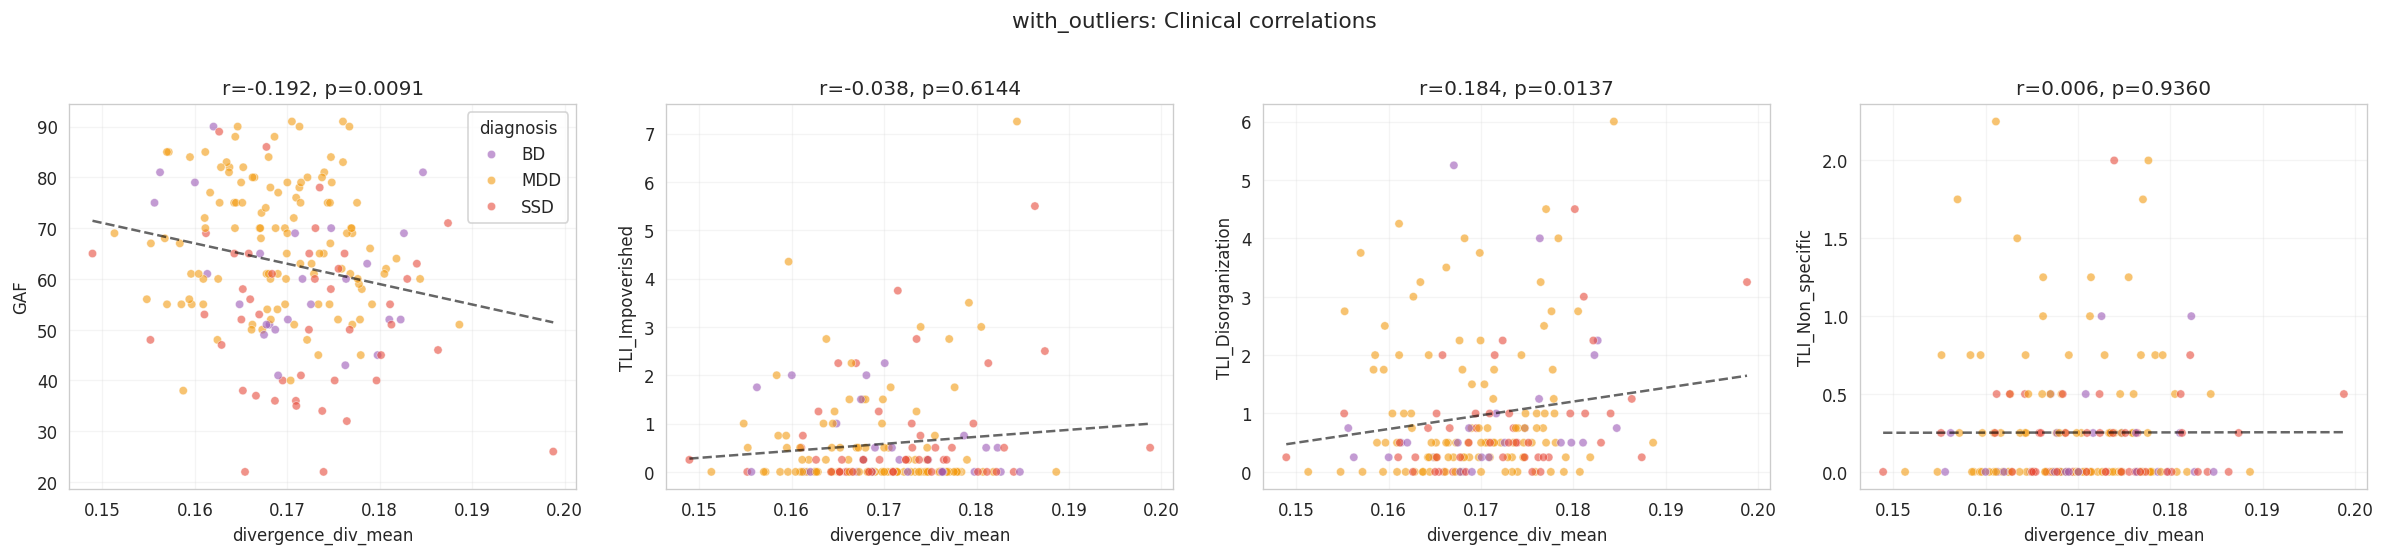

Saved: figures/divergence/with_outliers/03_diagnostic_groups.png


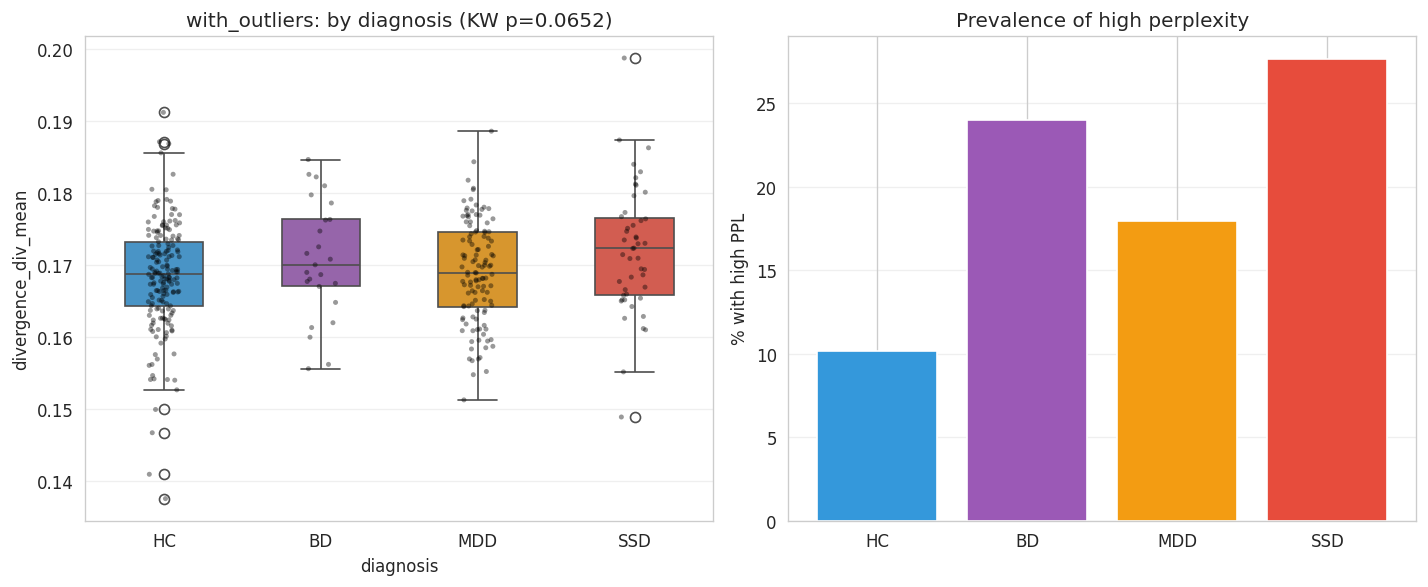

Saved: figures/divergence/with_outliers/04_extreme_groups.png


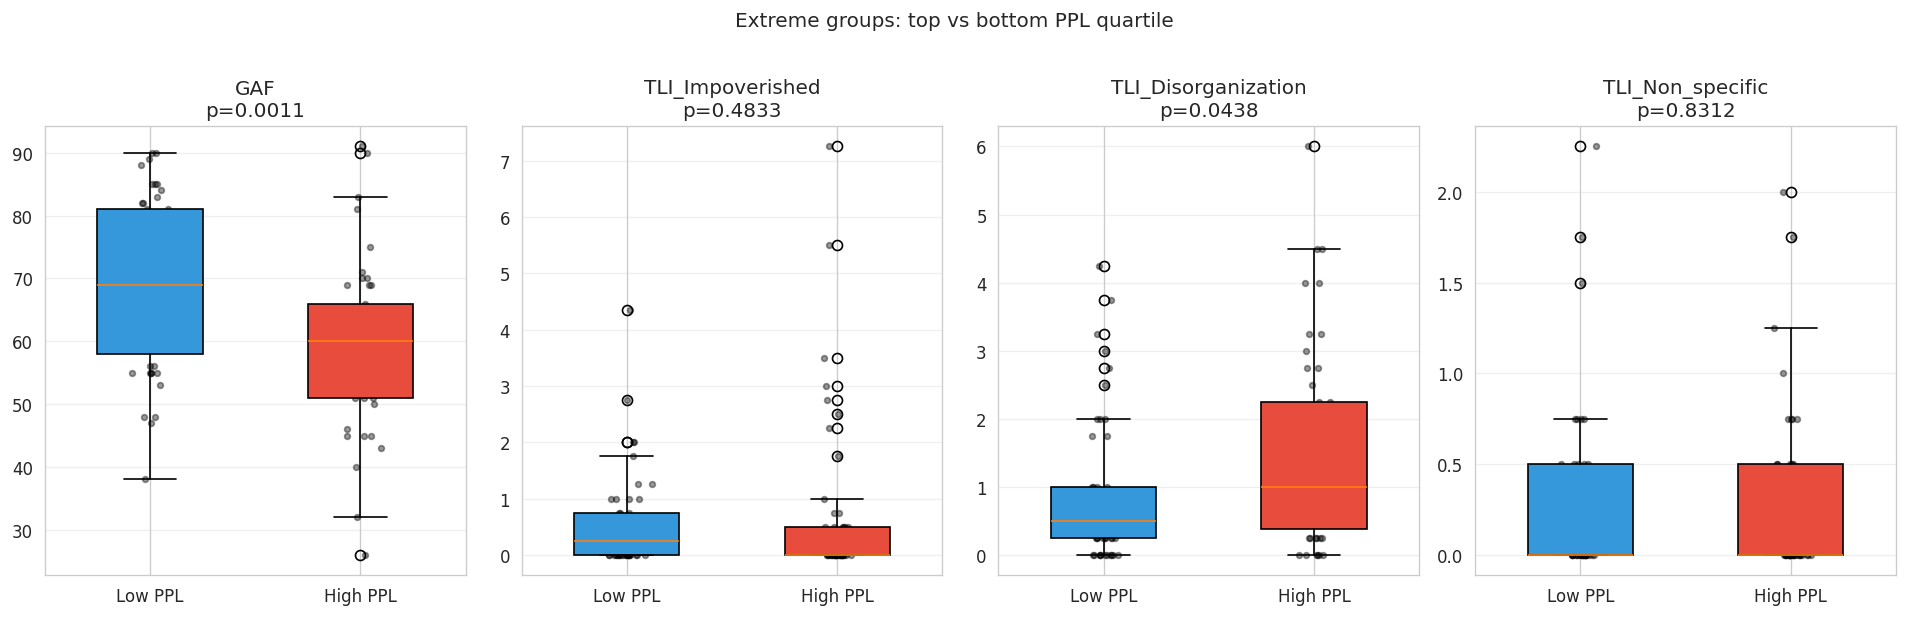

Saved: figures/divergence/with_outliers/05_tli_subscales.png


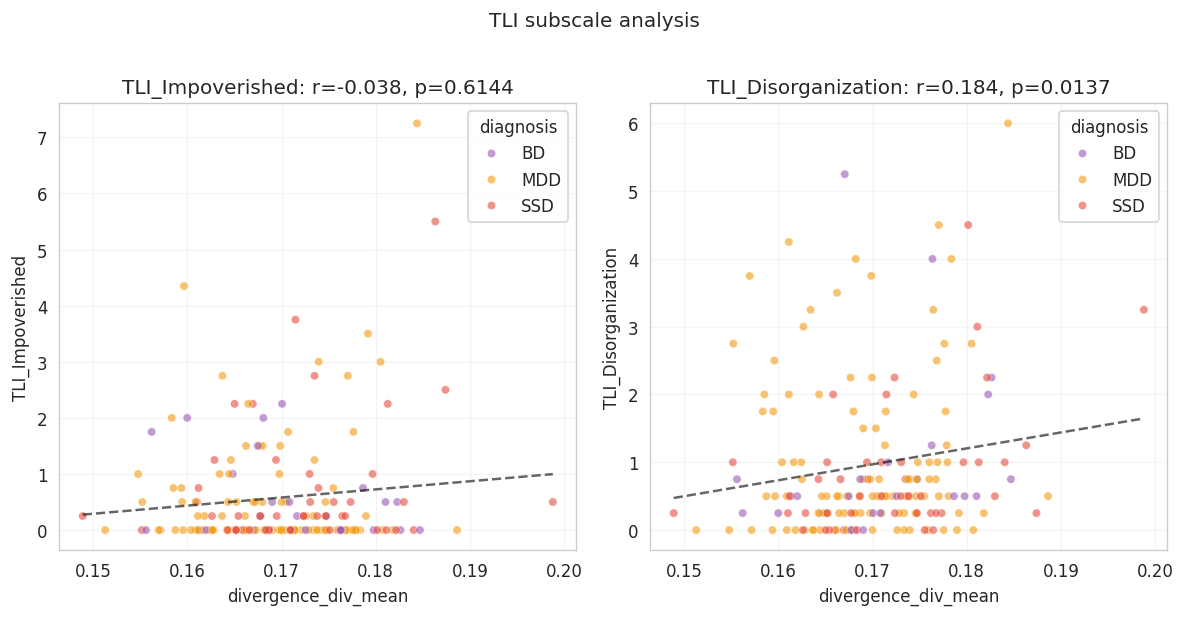


--- Deconfounding (with_outliers) ---
  Raw:          p(MW)=0.0890, d=0.213
  Residualized: p(MW)=0.1684, d=0.180

  Clinical correlations (raw vs residualized):
  Clinical Variable     r_raw    p_raw  n_raw   r_resid  p_resid  n_resid
                GAF -0.192409 0.009069    183 -0.183426 0.014818      176
   TLI_Impoverished -0.038013 0.614424    178 -0.006547 0.932473      170
TLI_Disorganization  0.184477 0.013698    178  0.129800 0.091596      170
   TLI_Non_specific  0.006057 0.936045    178 -0.017734 0.818452      170

  Kruskal-Wallis — Raw: H=7.222, p=0.0652
  Kruskal-Wallis — Resid: H=6.947, p=0.0736
Saved: figures/divergence/with_outliers/deconfounded/raw_vs_residualized.png


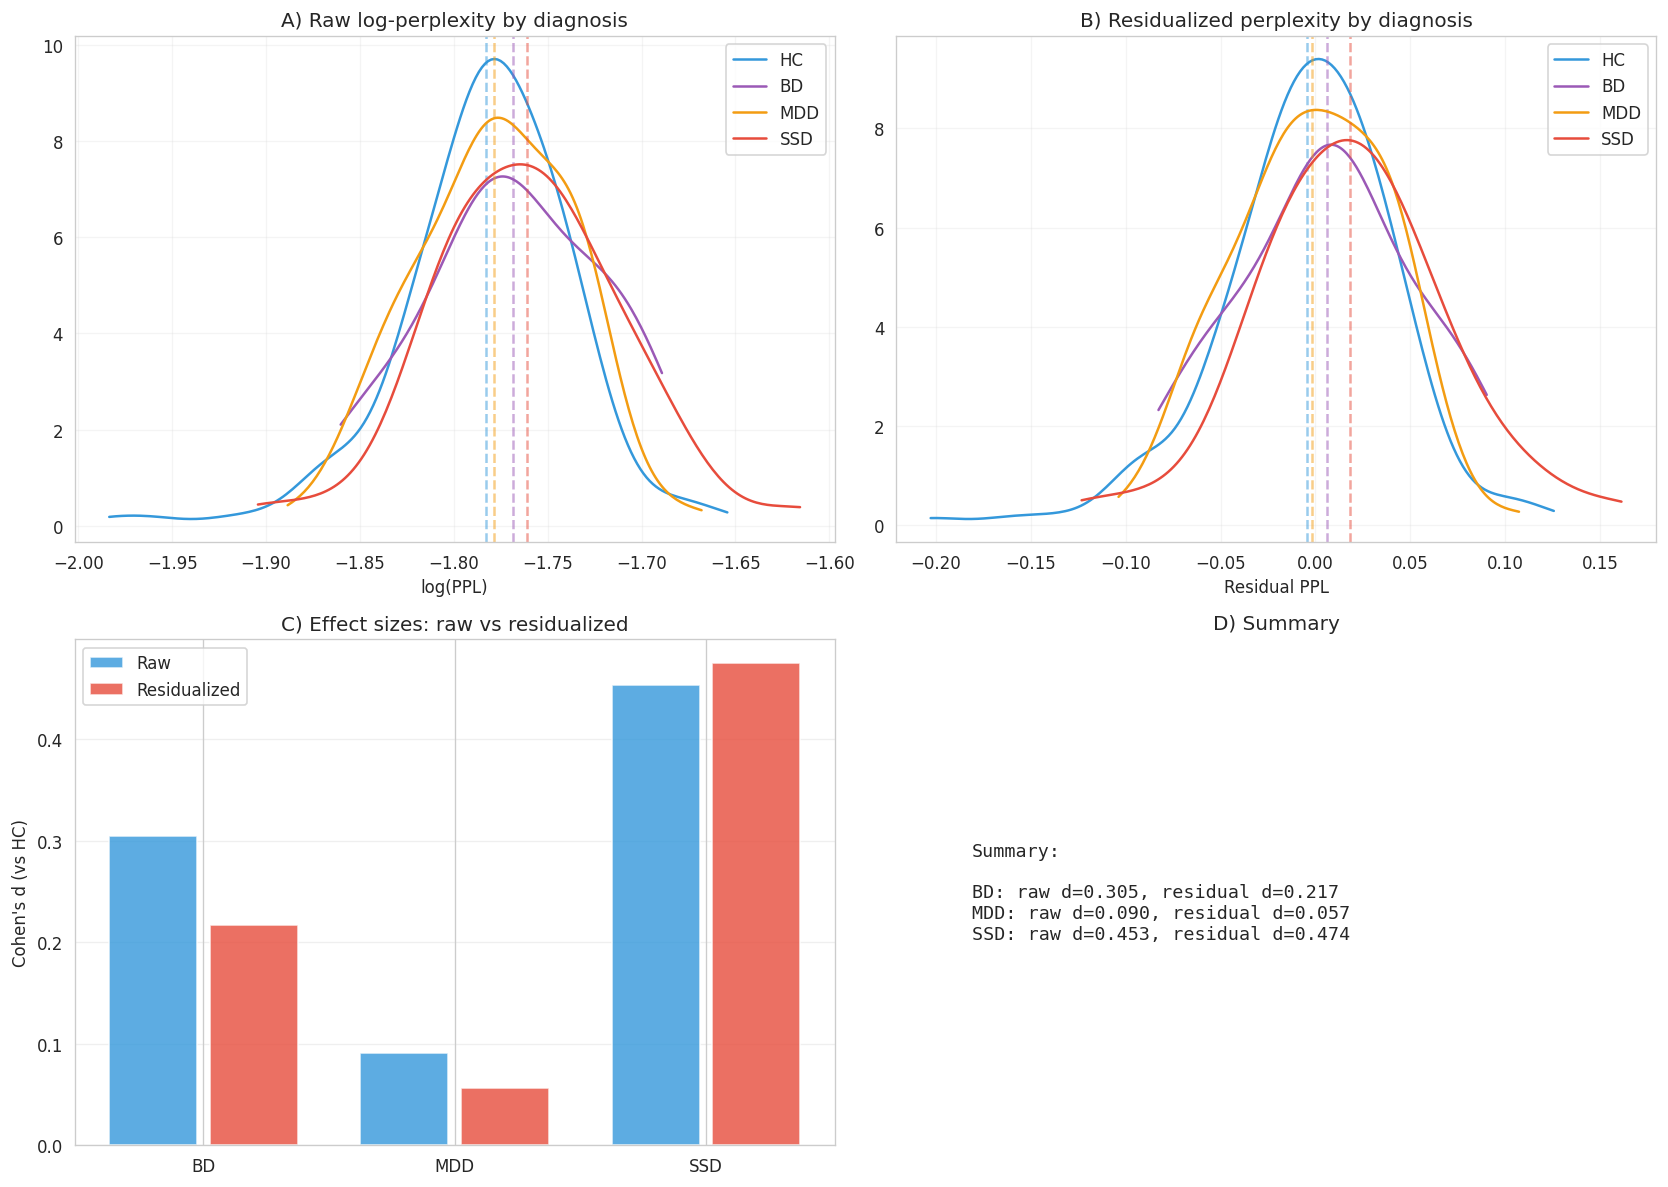

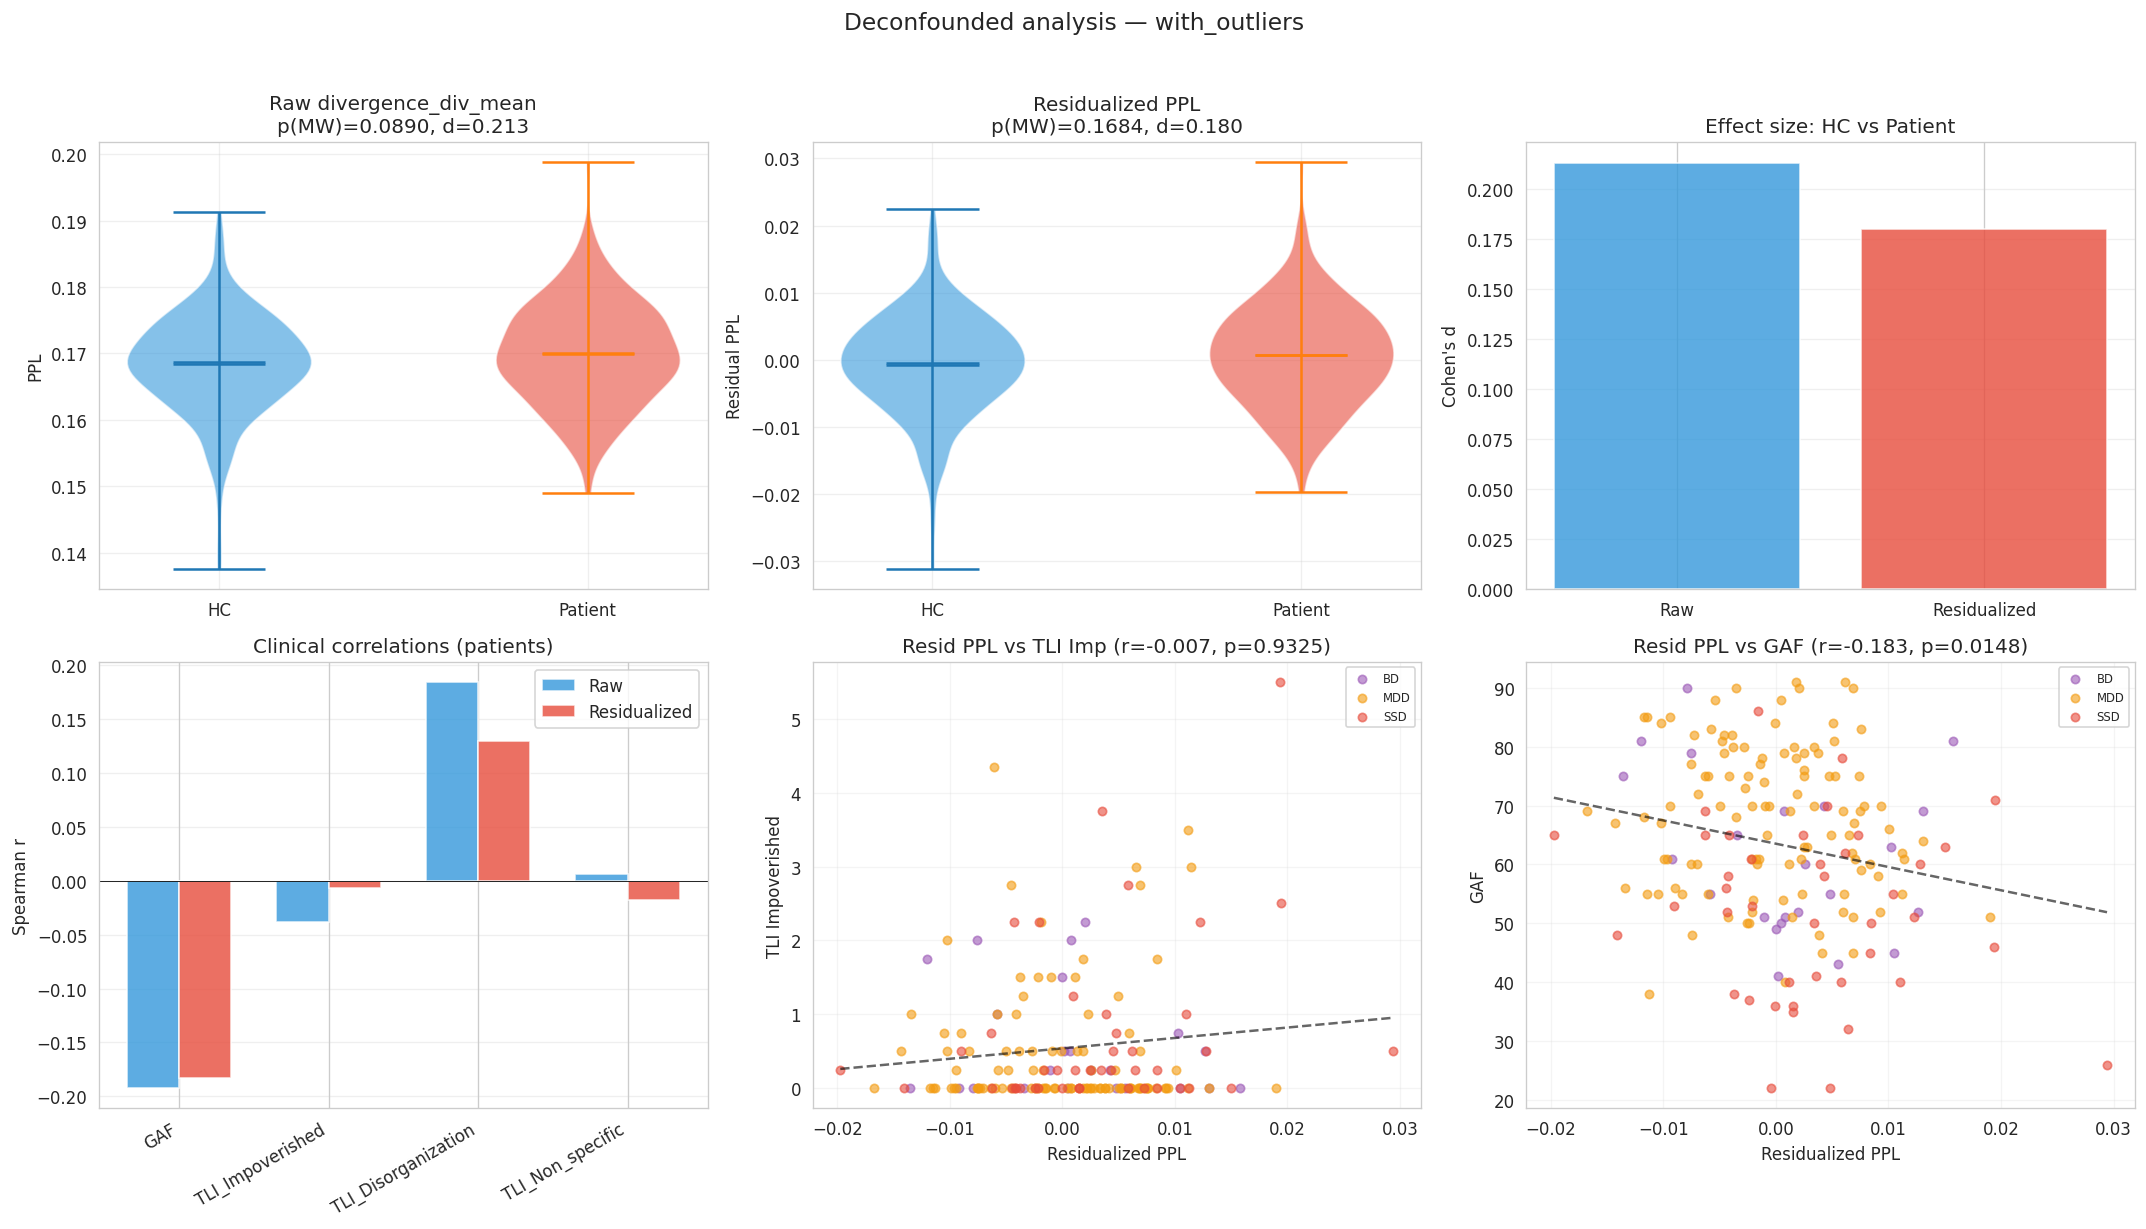


Setting: without_outliers | PPL variable: divergence_div_mean_wins
Saved: figures/divergence/without_outliers/01_group_boxplot.png


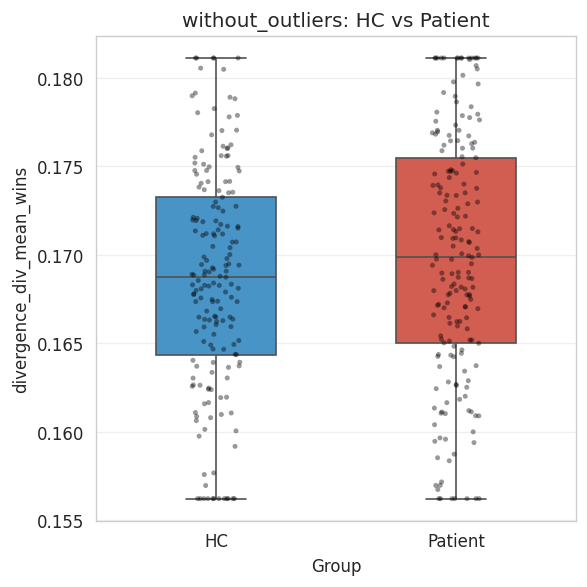


without_outliers — divergence_div_mean_wins:
  Variable: divergence_div_mean_wins
  Control (M±SD): 0.17±0.01
  Patient (M±SD): 0.17±0.01
  Control Median: 0.1687369483548241
  Patient Median: 0.16986176888147986
  t: 1.7844042350248408
  p(t): 0.07519079381312001
  U: 18446.0
  p(MW): 0.08918423447855153
  Cohens d: 0.18664495382407761
  r: -0.10280094460885425

Clinical correlations (without_outliers):
  Clinical Variable         r        p   n
                GAF -0.192645 0.008982 183
   TLI_Impoverished -0.040254 0.593694 178
TLI_Disorganization  0.184516 0.013678 178
   TLI_Non_specific  0.006737 0.928879 178
Saved: figures/divergence/without_outliers/02_clinical_scatter.png


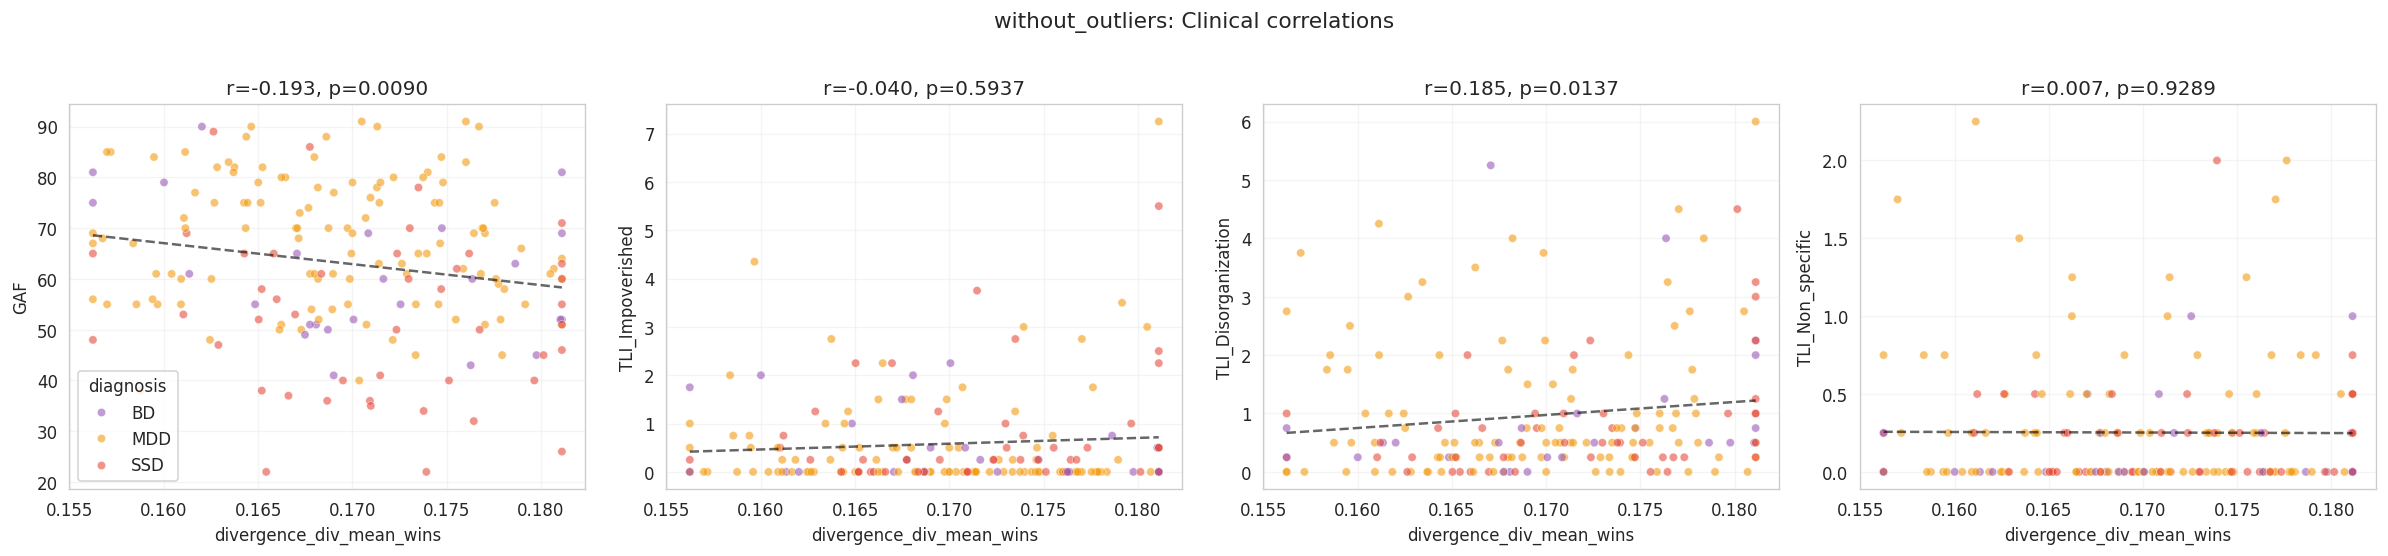

Saved: figures/divergence/without_outliers/03_diagnostic_groups.png


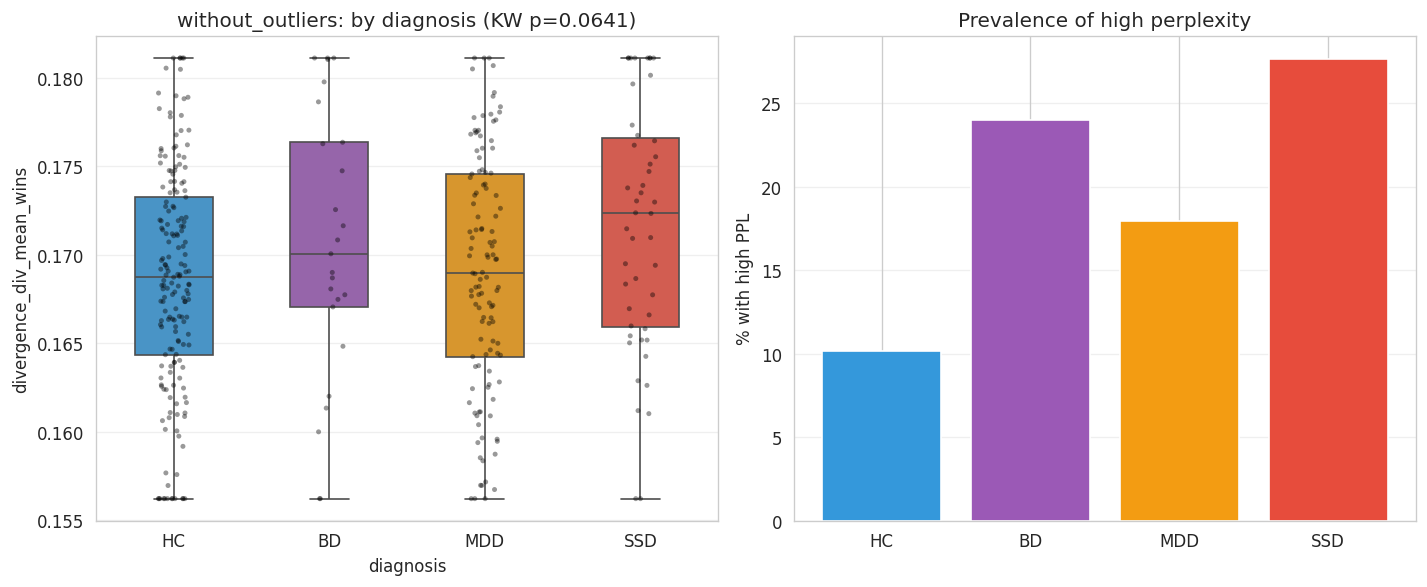

Saved: figures/divergence/without_outliers/04_extreme_groups.png


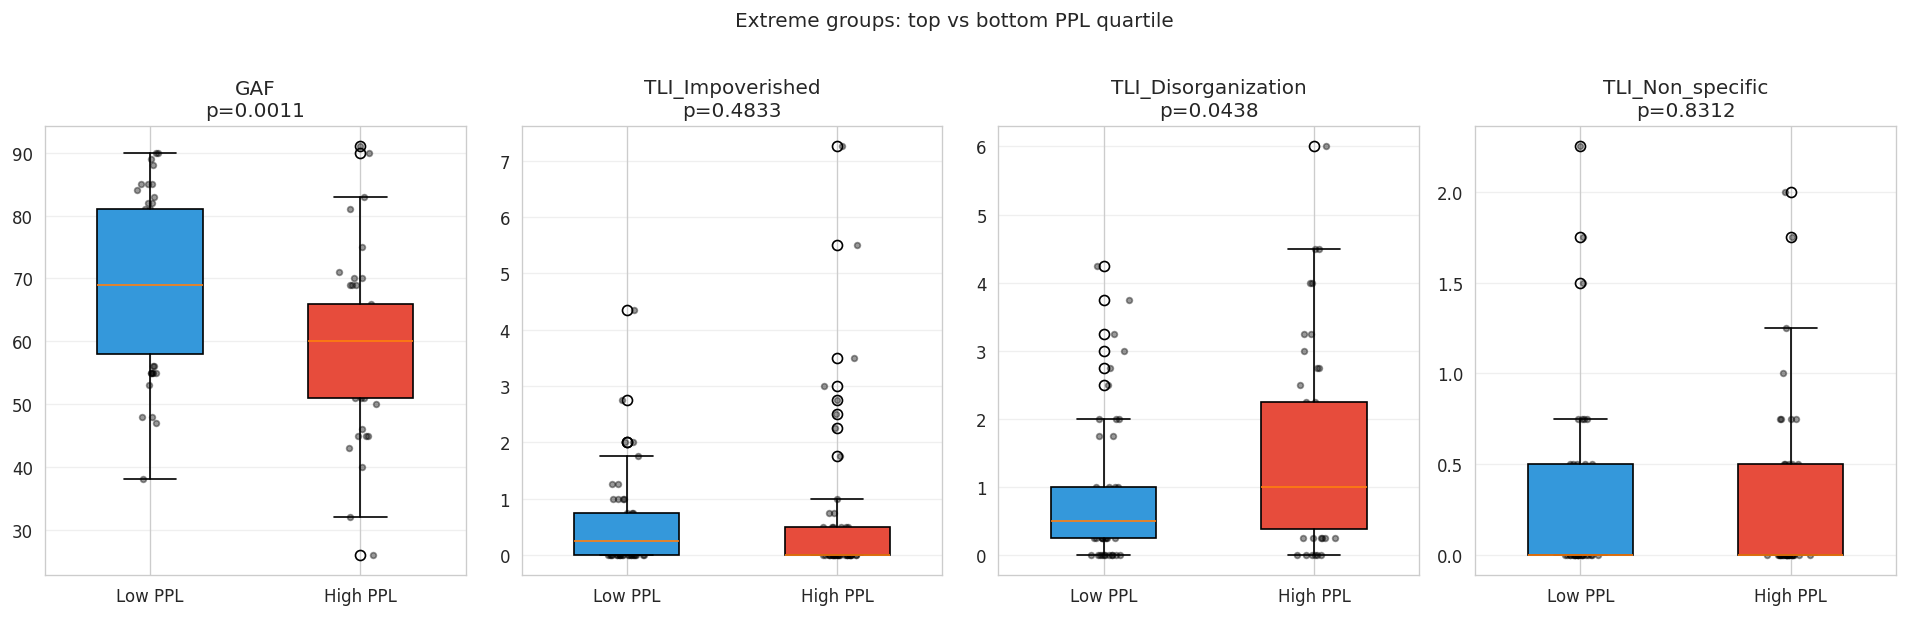

Saved: figures/divergence/without_outliers/05_tli_subscales.png


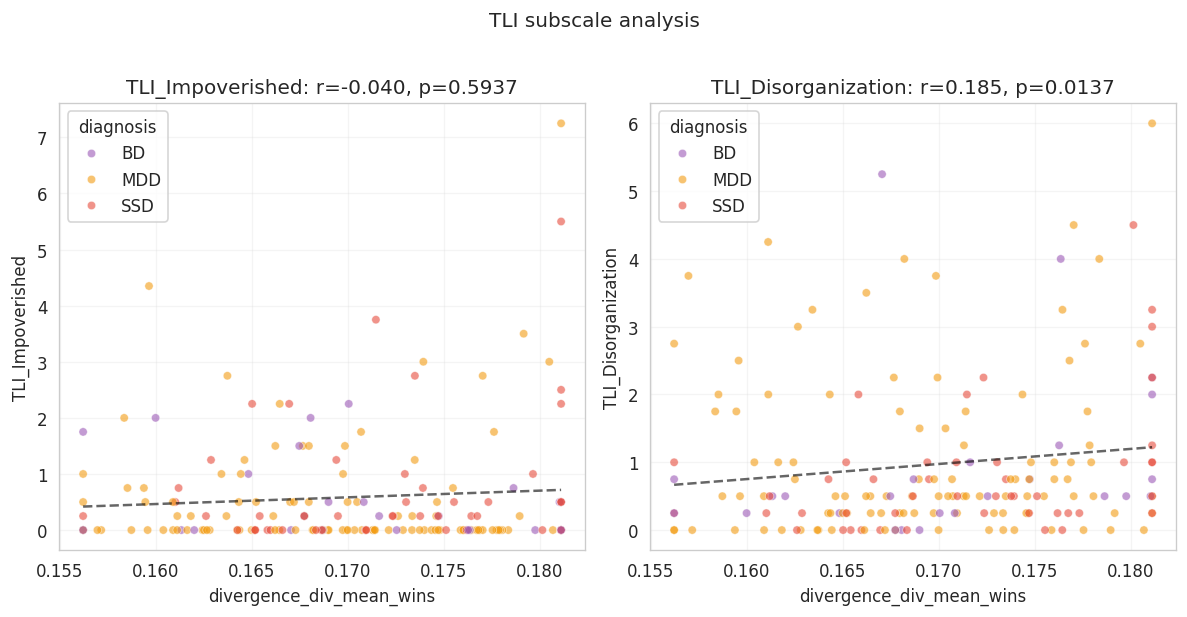


--- Deconfounding (without_outliers) ---
  Raw:          p(MW)=0.0892, d=0.187
  Residualized: p(MW)=0.1899, d=0.148

  Clinical correlations (raw vs residualized):
  Clinical Variable     r_raw    p_raw  n_raw   r_resid  p_resid  n_resid
                GAF -0.192645 0.008982    183 -0.177234 0.018614      176
   TLI_Impoverished -0.040254 0.593694    178 -0.021603 0.779767      170
TLI_Disorganization  0.184516 0.013678    178  0.136260 0.076430      170
   TLI_Non_specific  0.006737 0.928879    178 -0.013425 0.862059      170

  Kruskal-Wallis — Raw: H=7.259, p=0.0641
  Kruskal-Wallis — Resid: H=6.602, p=0.0857
Saved: figures/divergence/without_outliers/deconfounded/raw_vs_residualized.png


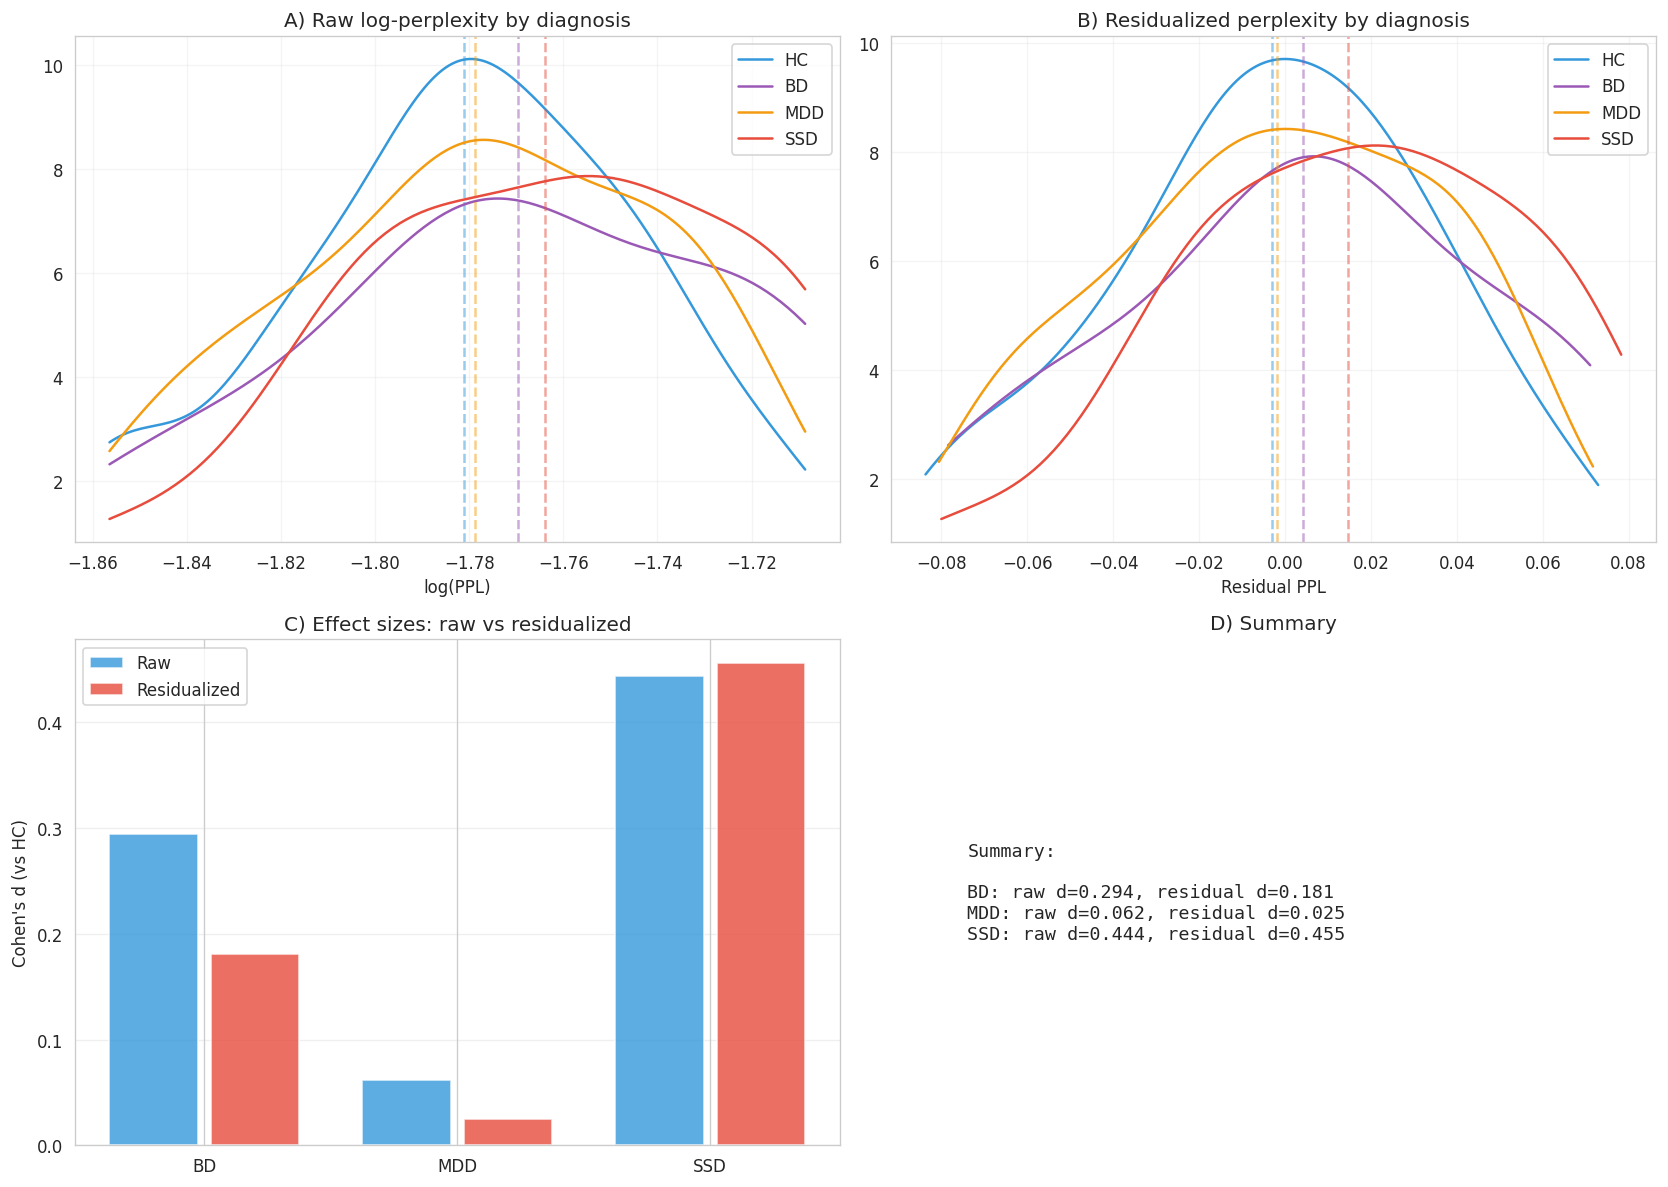

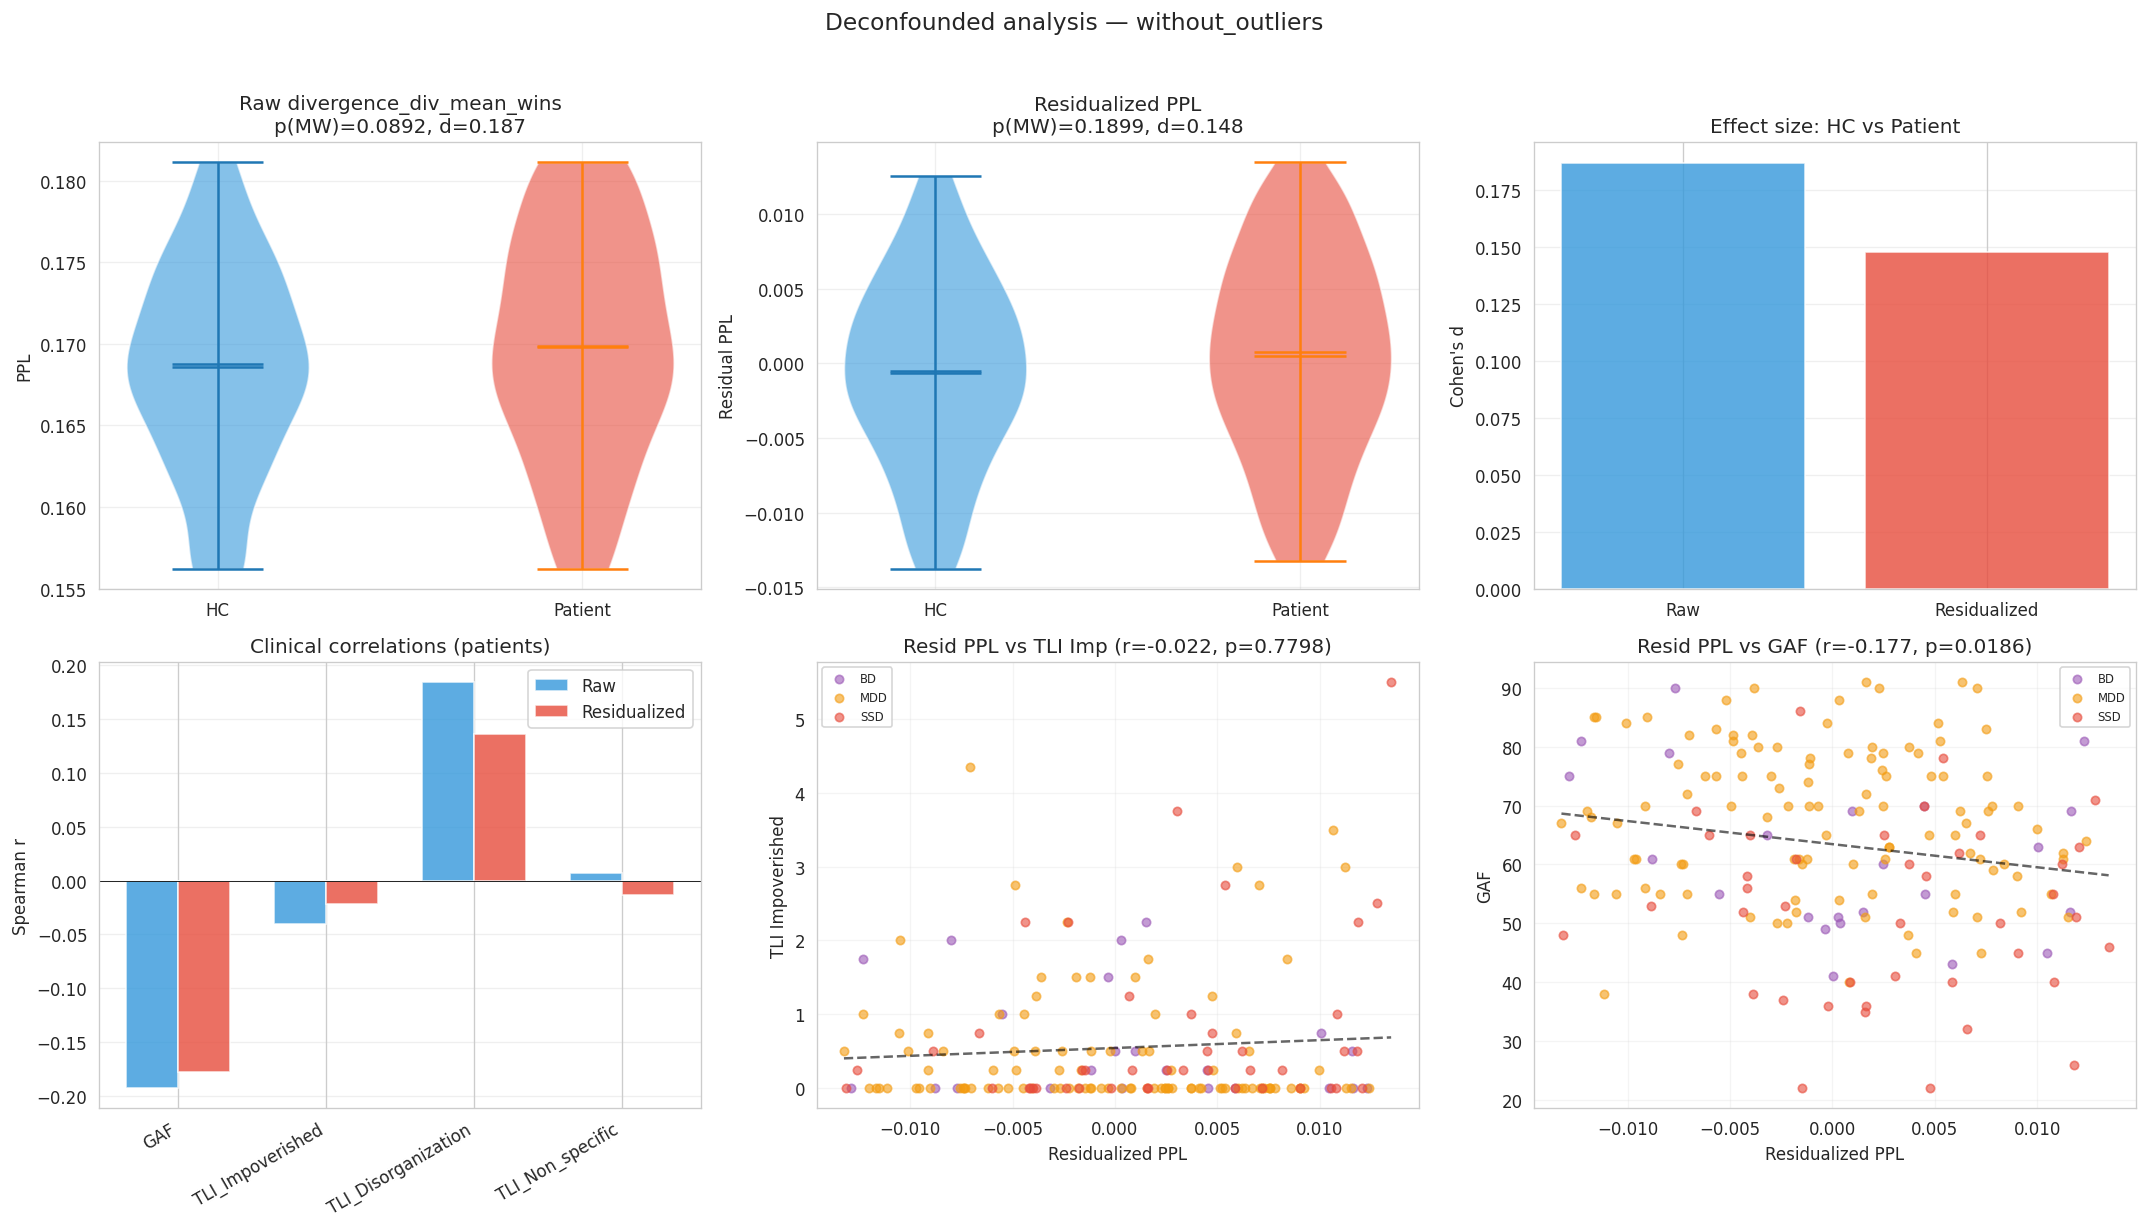


Setting: matched | PPL variable: divergence_div_mean
Saved: figures/divergence/matched/01_group_boxplot.png


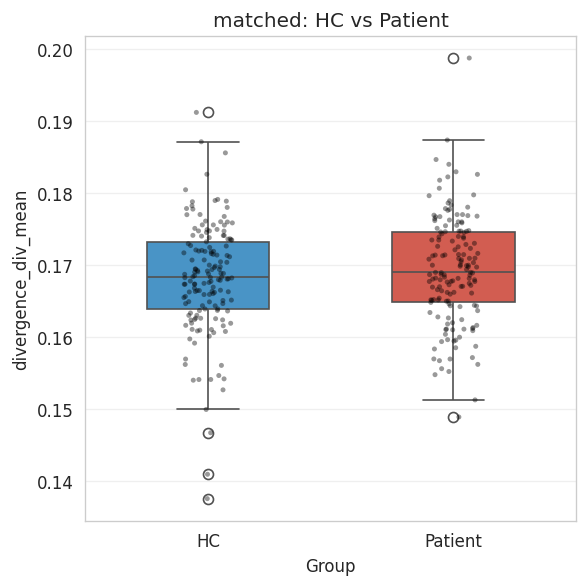


matched — divergence_div_mean:
  Variable: divergence_div_mean
  Control (M±SD): 0.17±0.01
  Patient (M±SD): 0.17±0.01
  Control Median: 0.16834180722845357
  Patient Median: 0.16900604674893038
  t: 1.385658145757088
  p(t): 0.1668409988630716
  U: 13193.0
  p(MW): 0.2805500995701822
  Cohens d: 0.15639442611889004
  r: -0.07046939023895482

Clinical correlations (matched):
  Clinical Variable         r        p   n
                GAF -0.139392 0.084683 154
   TLI_Impoverished -0.108354 0.189901 148
TLI_Disorganization  0.151816 0.065481 148
   TLI_Non_specific -0.034121 0.680563 148
Saved: figures/divergence/matched/02_clinical_scatter.png


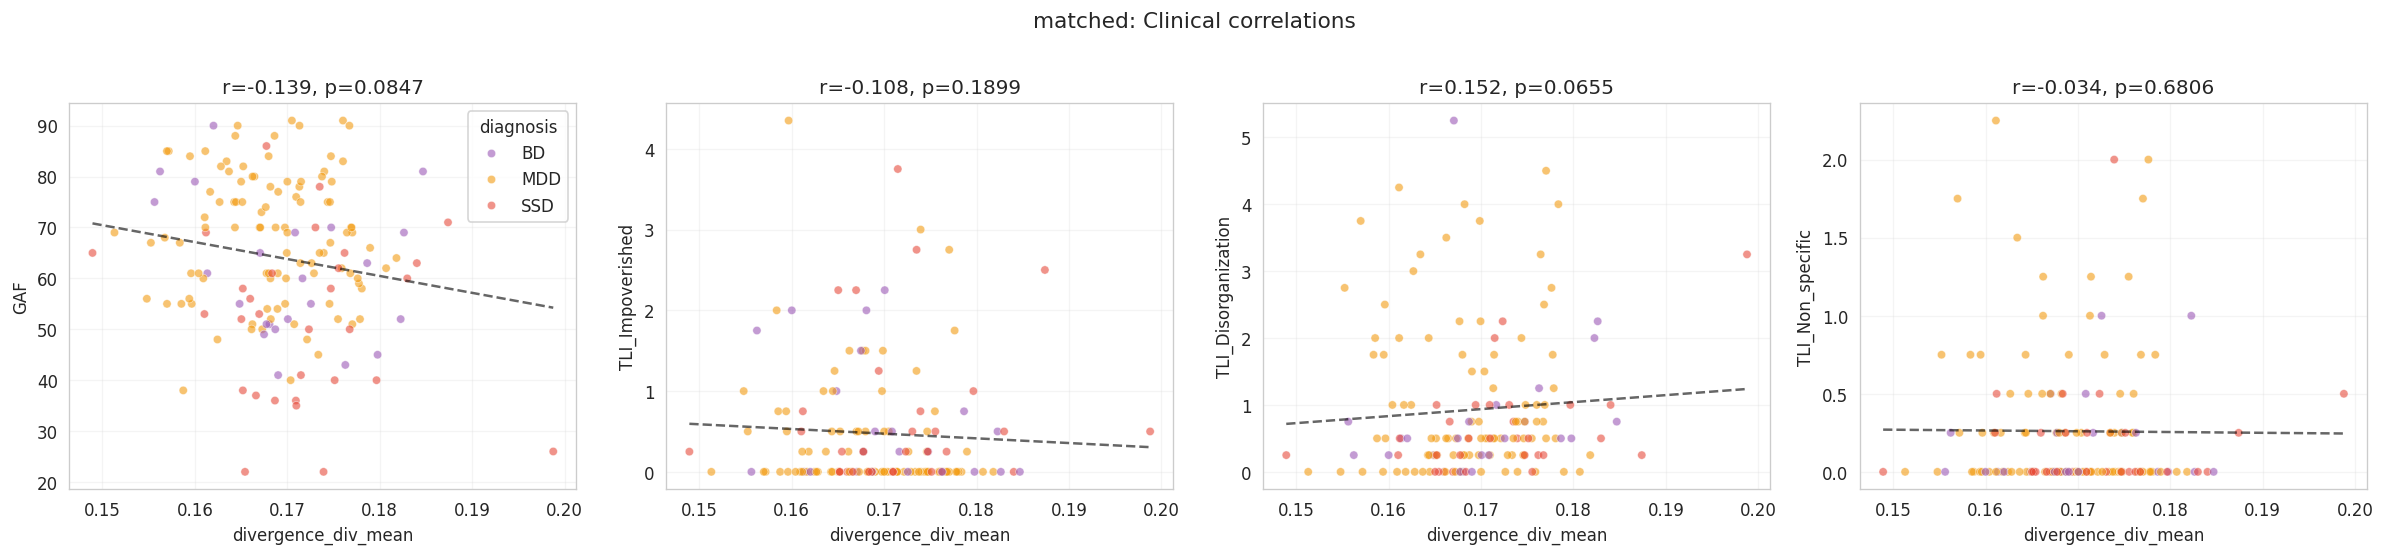

Saved: figures/divergence/matched/03_diagnostic_groups.png


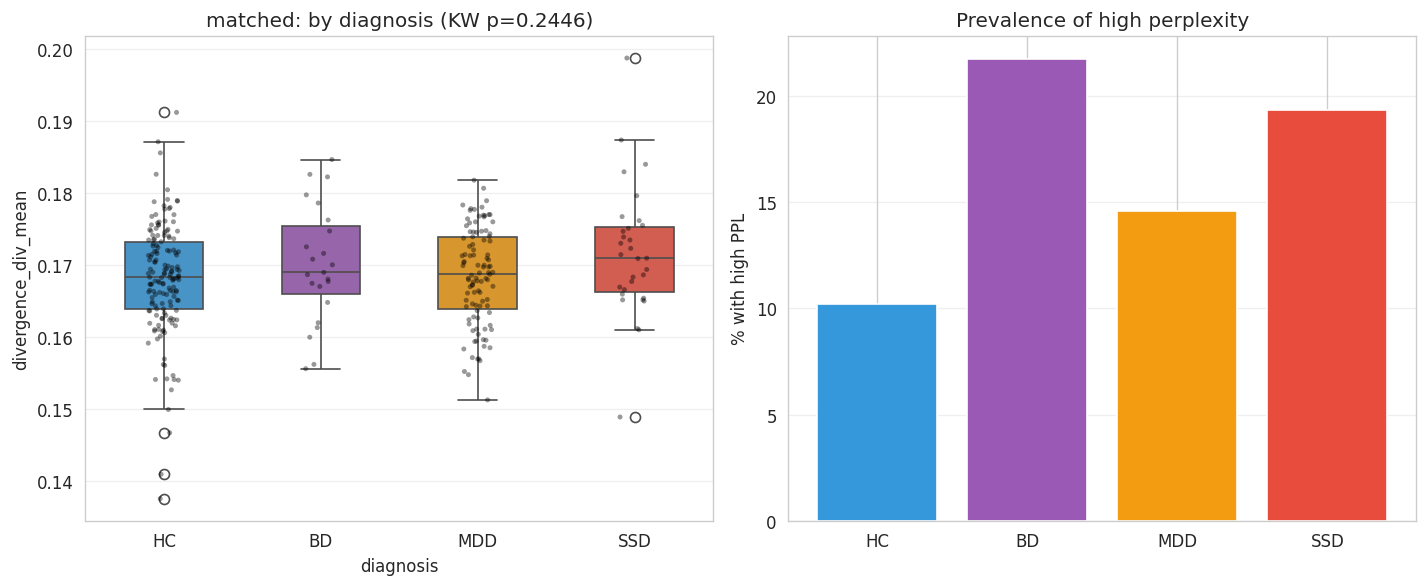

Saved: figures/divergence/matched/04_extreme_groups.png


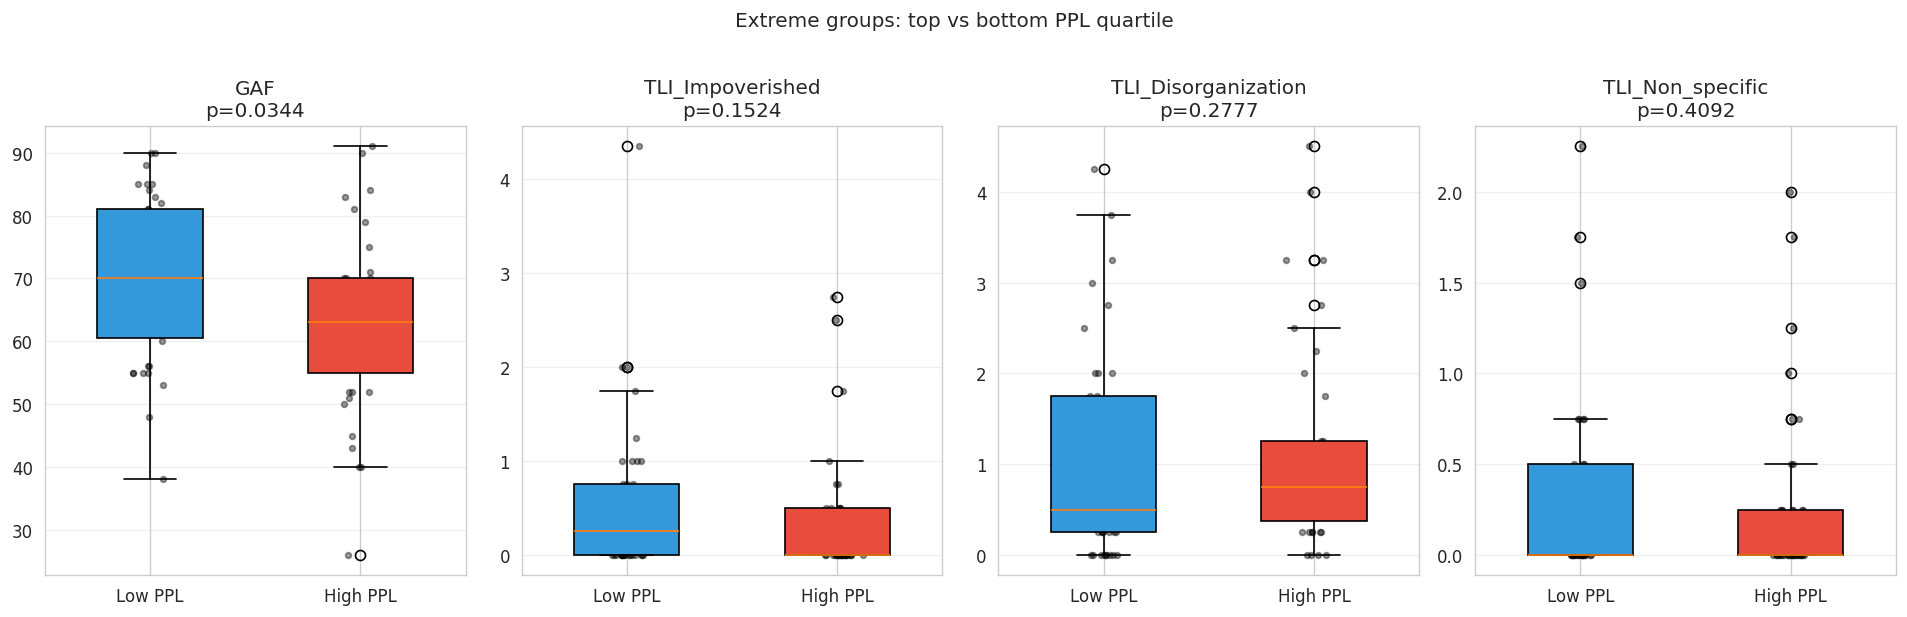

Saved: figures/divergence/matched/05_tli_subscales.png


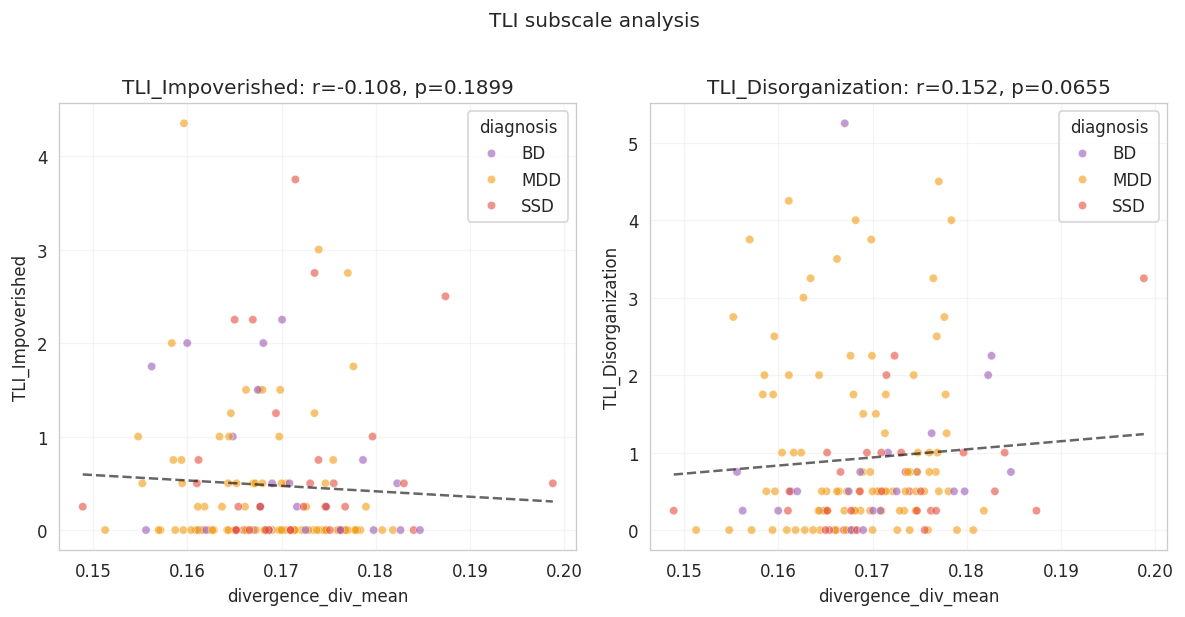


--- Deconfounding (matched) ---
  Raw:          p(MW)=0.2806, d=0.156
  Residualized: p(MW)=0.2517, d=0.164

  Clinical correlations (raw vs residualized):
  Clinical Variable     r_raw    p_raw  n_raw   r_resid  p_resid  n_resid
                GAF -0.139392 0.084683    154 -0.152833 0.058452      154
   TLI_Impoverished -0.108354 0.189901    148 -0.043386 0.600568      148
TLI_Disorganization  0.151816 0.065481    148  0.114155 0.167125      148
   TLI_Non_specific -0.034121 0.680563    148 -0.046316 0.576178      148

  Kruskal-Wallis — Raw: H=4.161, p=0.2446
  Kruskal-Wallis — Resid: H=4.902, p=0.1791
Saved: figures/divergence/matched/deconfounded/raw_vs_residualized.png


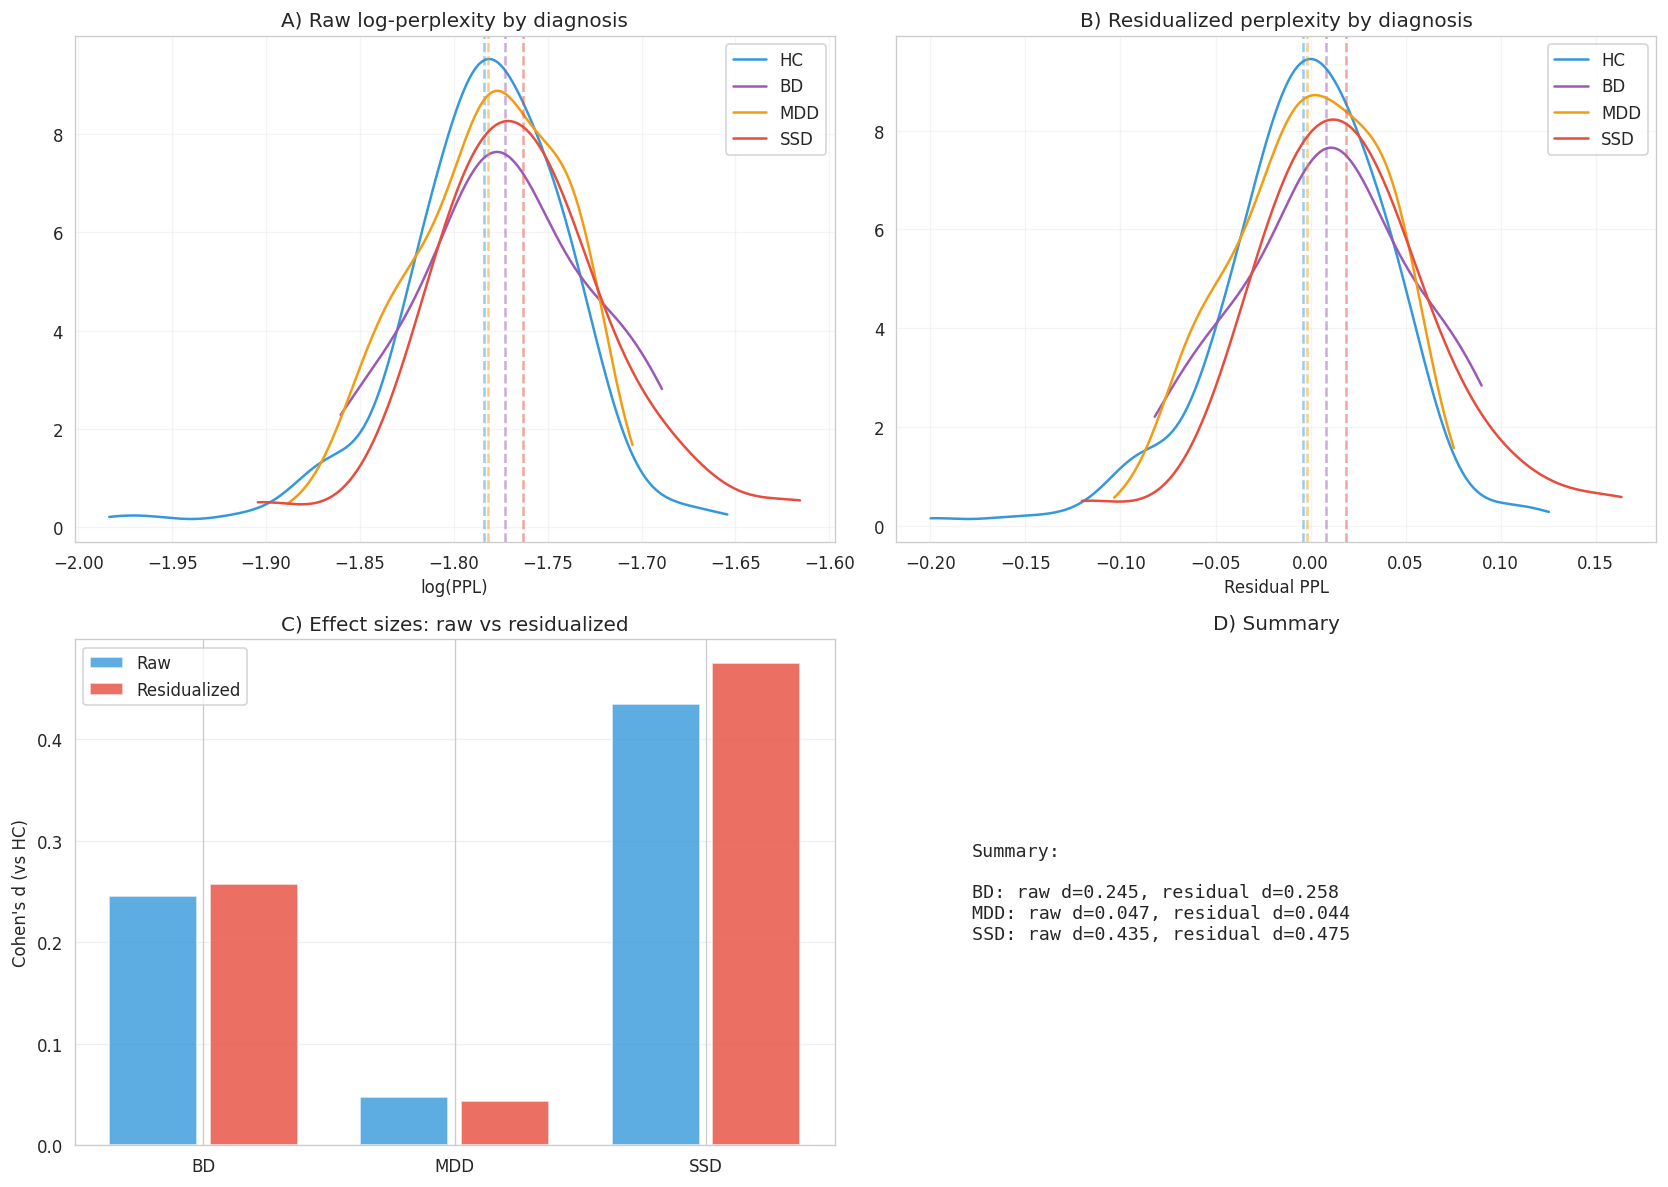

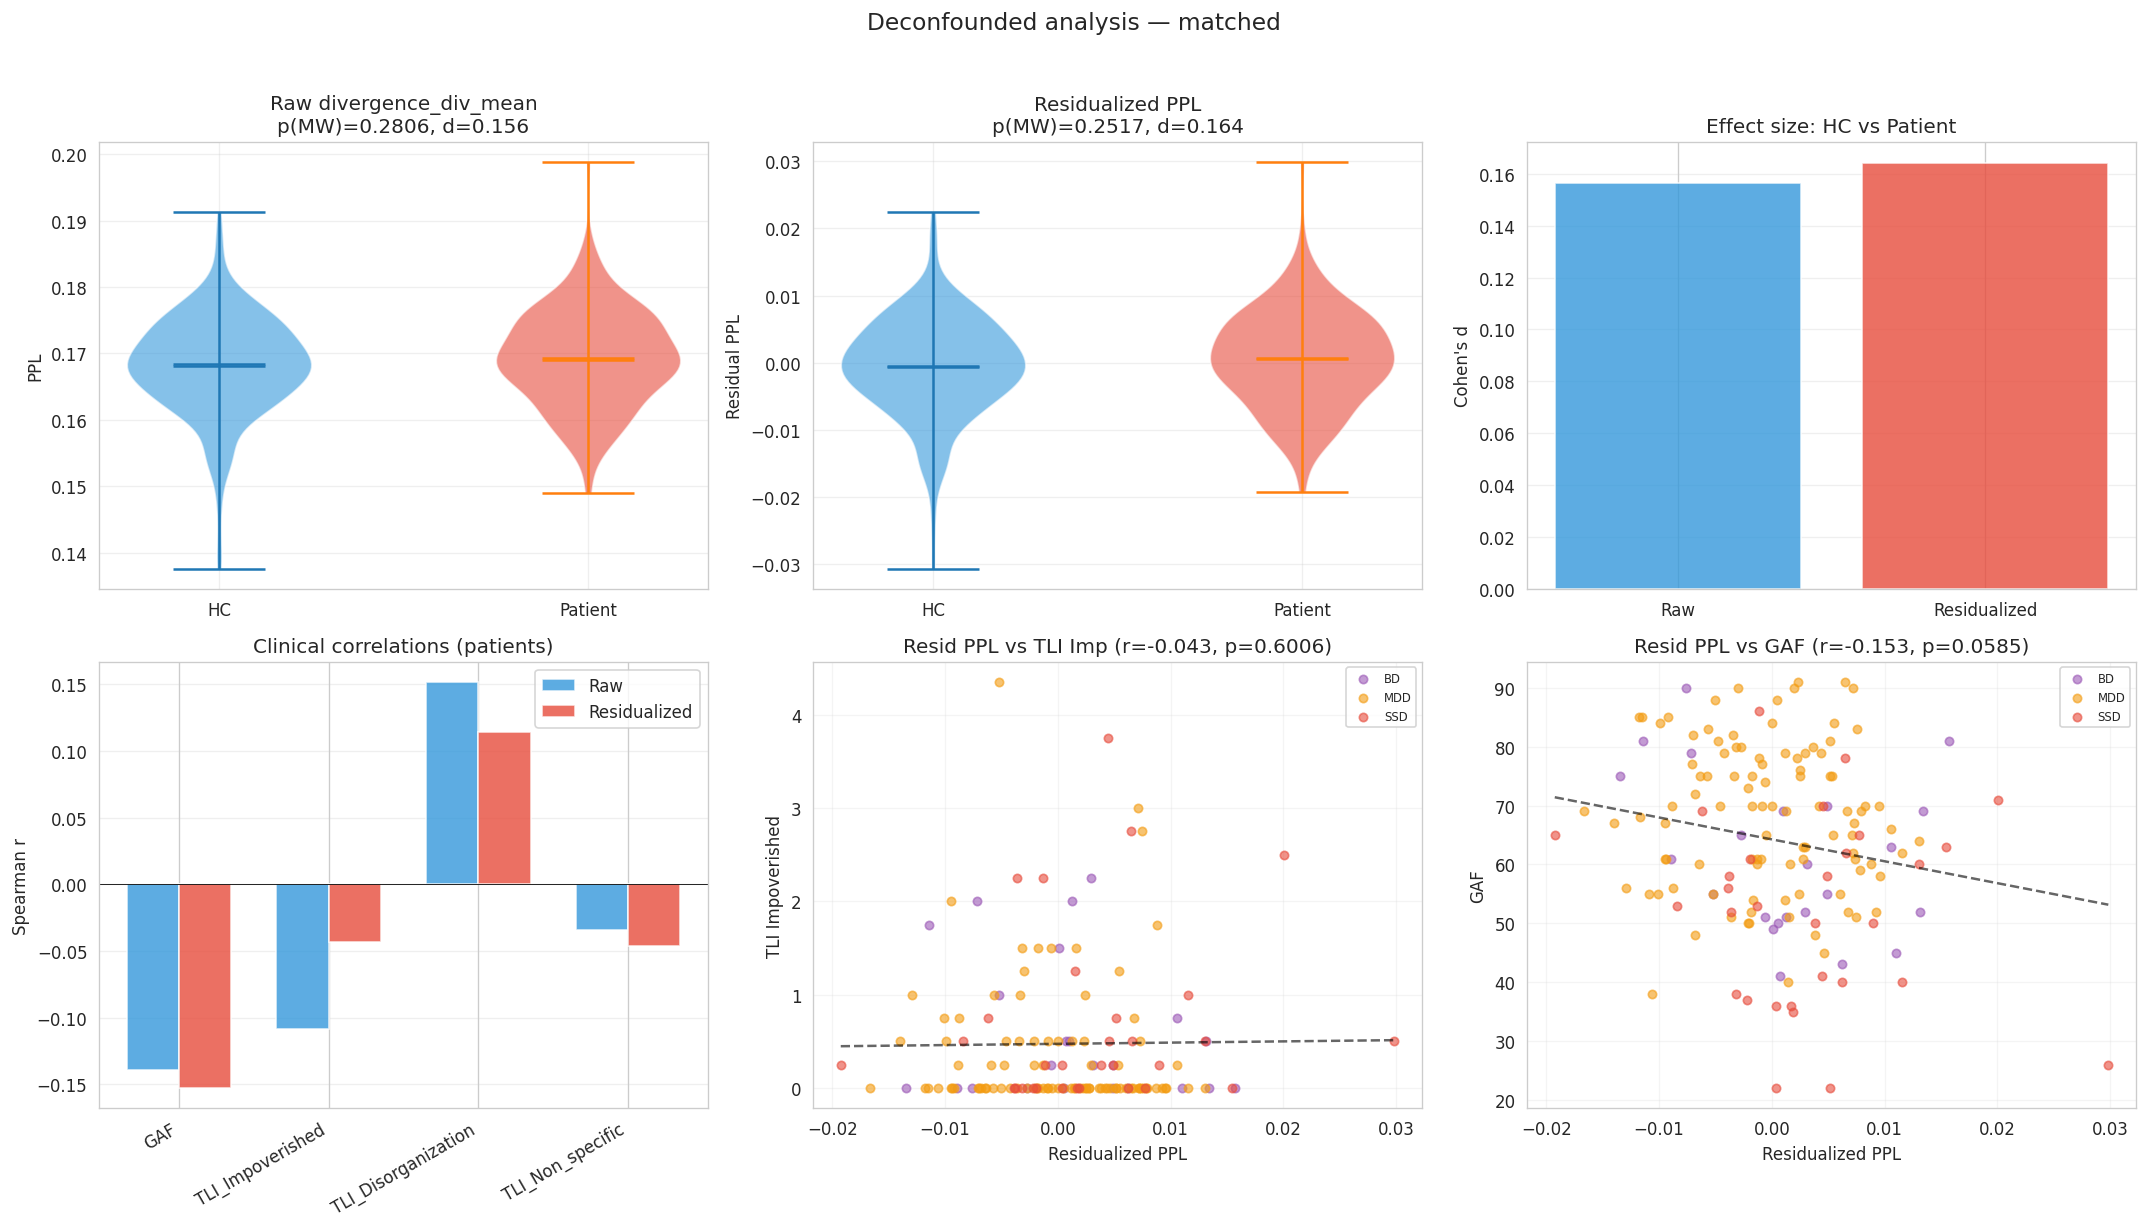

In [ ]:
import statsmodels.api as sm

# Map each setting to the PPL variable it should use
setting_ppl_vars = {
    "with_outliers": PPL_VAR,
    "without_outliers": f"{PPL_VAR}_wins",
    "matched": PPL_VAR,
}

all_results = {}
all_corr_dfs = {}

for setting_name, setting_df in settings.items():
    ppl_col = setting_ppl_vars[setting_name]
    print(f"\n{'='*60}")
    print(f"Setting: {setting_name} | PPL variable: {ppl_col}")
    print(f"{'='*60}")

    # ── Standard analysis ─────────────────────────────────────────
    result = plot_setting(
        df=setting_df,
        ppl_var=ppl_col,
        setting_name=setting_name,
        figure_dir=FIGURE_DIR,
        clinical_vars=clinical_vars,
    )

    # ── Deconfounding analysis ────────────────────────────────────
    print(f"\n--- Deconfounding ({setting_name}) ---")
    sdf = setting_df.copy()
    sdf["log_words"] = np.log1p(sdf[WC_VAR])
    confounders = ["log_words"]
    if "education" in sdf.columns:
        confounders.append("education")

    resid = residualize_ppl(sdf, ppl_col, confounders)
    resid_col = f"{ppl_col}_resid"
    sdf[resid_col] = np.nan
    sdf.loc[resid.index, resid_col] = resid

    # Group comparison: raw vs residualized
    comp_raw = group_comparison(sdf, ppl_col)
    comp_resid = group_comparison(sdf.dropna(subset=[resid_col]), resid_col)
    print(f"  Raw:          p(MW)={comp_raw['p(MW)']:.4f}, d={comp_raw['Cohens d']:.3f}")
    print(f"  Residualized: p(MW)={comp_resid['p(MW)']:.4f}, d={comp_resid['Cohens d']:.3f}")

    # Clinical correlations: raw vs residualized
    patients_s = sdf[sdf["is_patient"] == 1].copy()
    corr_raw = clinical_correlations(patients_s, ppl_col, clinical_vars)
    corr_resid = clinical_correlations(
        patients_s.dropna(subset=[resid_col]), resid_col, clinical_vars
    )
    merged_corr = corr_raw.merge(
        corr_resid, on="Clinical Variable", suffixes=("_raw", "_resid")
    )
    print(f"\n  Clinical correlations (raw vs residualized):")
    print(merged_corr.to_string(index=False))

    # Pairwise vs HC: raw vs residualized
    from functions.analysis.statistics import pairwise_vs_hc, kruskal_wallis_test
    pw_raw = pairwise_vs_hc(sdf, ppl_col)
    pw_resid = pairwise_vs_hc(sdf.dropna(subset=[resid_col]), resid_col)
    kw_raw_stat, kw_raw_p = kruskal_wallis_test(sdf, ppl_col)
    kw_res_stat, kw_res_p = kruskal_wallis_test(
        sdf.dropna(subset=[resid_col]), resid_col
    )
    print(f"\n  Kruskal-Wallis — Raw: H={kw_raw_stat:.3f}, p={kw_raw_p:.4f}")
    print(f"  Kruskal-Wallis — Resid: H={kw_res_stat:.3f}, p={kw_res_p:.4f}")

    # ── Deconfounded visualisation ────────────────────────────────
    deconf_dir = os.path.join(FIGURE_DIR, setting_name, "deconfounded")
    os.makedirs(deconf_dir, exist_ok=True)

    # Plot 1: raw vs residualized (uses plotting_service helper)
    plot_raw_vs_residualized(
        sdf, ppl_col, WC_VAR,
        save_path=os.path.join(deconf_dir, "raw_vs_residualized.png"),
    )

    # Plot 2: deconfounded comparison figure
    from functions.plotting.plots import DIAG_ORDER, DIAG_COLORS
    from scipy.stats import spearmanr as _spearmanr

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # Row 1 col 0: Raw PPL violin
    ax = axes[0, 0]
    for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
        vals = sdf[sdf["is_patient"] == is_pat][ppl_col].dropna()
        parts = ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
        for pc in parts["bodies"]:
            pc.set_facecolor(clr); pc.set_alpha(0.6)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
    ax.set_title(f"Raw {ppl_col}\np(MW)={comp_raw['p(MW)']:.4f}, d={comp_raw['Cohens d']:.3f}")
    ax.set_ylabel("PPL"); ax.grid(alpha=0.3)

    # Row 1 col 1: Residualized PPL violin
    ax = axes[0, 1]
    for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
        vals = sdf[sdf["is_patient"] == is_pat][resid_col].dropna()
        parts = ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
        for pc in parts["bodies"]:
            pc.set_facecolor(clr); pc.set_alpha(0.6)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
    ax.set_title(f"Residualized PPL\np(MW)={comp_resid['p(MW)']:.4f}, d={comp_resid['Cohens d']:.3f}")
    ax.set_ylabel("Residual PPL"); ax.grid(alpha=0.3)

    # Row 1 col 2: Cohen's d comparison
    ax = axes[0, 2]
    ax.bar(["Raw", "Residualized"], [comp_raw["Cohens d"], comp_resid["Cohens d"]],
           color=["#3498DB", "#E74C3C"], alpha=0.8)
    ax.set_ylabel("Cohen's d"); ax.set_title("Effect size: HC vs Patient")
    ax.grid(axis="y", alpha=0.3); ax.axhline(0, color="black", lw=0.5)

    # Row 2 col 0: Clinical correlations bar chart
    ax = axes[1, 0]
    x = np.arange(len(clinical_vars))
    w = 0.35
    bars_raw = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_raw"]
    bars_res = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_resid"]
    ax.bar(x - w/2, bars_raw, w, label="Raw", color="#3498DB", alpha=0.8)
    ax.bar(x + w/2, bars_res, w, label="Residualized", color="#E74C3C", alpha=0.8)
    ax.set_xticks(x); ax.set_xticklabels(clinical_vars, rotation=30, ha="right")
    ax.set_ylabel("Spearman r"); ax.set_title("Clinical correlations (patients)")
    ax.legend(); ax.axhline(0, color="black", lw=0.5); ax.grid(axis="y", alpha=0.3)

    # Row 2 col 1: Scatter — residualized PPL vs TLI Impoverished
    ax = axes[1, 1]
    sub = patients_s[[resid_col, "TLI_Impoverished", "diagnosis"]].dropna()
    if len(sub) >= 5:
        diags = [d for d in DIAG_ORDER if d in sub["diagnosis"].values]
        for dx in diags:
            s = sub[sub["diagnosis"] == dx]
            ax.scatter(s[resid_col], s["TLI_Impoverished"], color=DIAG_COLORS.get(dx, "#888"),
                       label=dx, alpha=0.6, s=25)
        r, p = _spearmanr(sub[resid_col], sub["TLI_Impoverished"])
        z = np.polyfit(sub[resid_col], sub["TLI_Impoverished"], 1)
        xs = np.linspace(sub[resid_col].min(), sub[resid_col].max(), 100)
        ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
        ax.set_xlabel("Residualized PPL"); ax.set_ylabel("TLI Impoverished")
        ax.set_title(f"Resid PPL vs TLI Imp (r={r:.3f}, p={p:.4f})")
        ax.legend(fontsize=7); ax.grid(alpha=0.2)

    # Row 2 col 2: Scatter — residualized PPL vs GAF
    ax = axes[1, 2]
    sub = patients_s[[resid_col, "GAF", "diagnosis"]].dropna()
    if len(sub) >= 5:
        diags = [d for d in DIAG_ORDER if d in sub["diagnosis"].values]
        for dx in diags:
            s = sub[sub["diagnosis"] == dx]
            ax.scatter(s[resid_col], s["GAF"], color=DIAG_COLORS.get(dx, "#888"),
                       label=dx, alpha=0.6, s=25)
        r, p = _spearmanr(sub[resid_col], sub["GAF"])
        z = np.polyfit(sub[resid_col], sub["GAF"], 1)
        xs = np.linspace(sub[resid_col].min(), sub[resid_col].max(), 100)
        ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
        ax.set_xlabel("Residualized PPL"); ax.set_ylabel("GAF")
        ax.set_title(f"Resid PPL vs GAF (r={r:.3f}, p={p:.4f})")
        ax.legend(fontsize=7); ax.grid(alpha=0.2)

    fig.suptitle(f"Deconfounded analysis — {setting_name}", fontsize=14, y=1.02)
    fig.tight_layout()
    fig.savefig(os.path.join(deconf_dir, "deconfounded_analysis.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # ── Store results ─────────────────────────────────────────────
    result["deconfounded"] = {
        "comparison_raw": comp_raw,
        "comparison_resid": comp_resid,
        "correlations_raw": corr_raw,
        "correlations_resid": corr_resid,
        "merged_correlations": merged_corr,
        "pairwise_raw": pw_raw,
        "pairwise_resid": pw_resid,
        "kruskal_raw": (kw_raw_stat, kw_raw_p),
        "kruskal_resid": (kw_res_stat, kw_res_p),
    }
    all_results[setting_name] = result
    all_corr_dfs[setting_name] = result["correlations"]

## 4. Cross-setting comparison

Saved: figures/divergence/cross_setting/robustness_bar.png


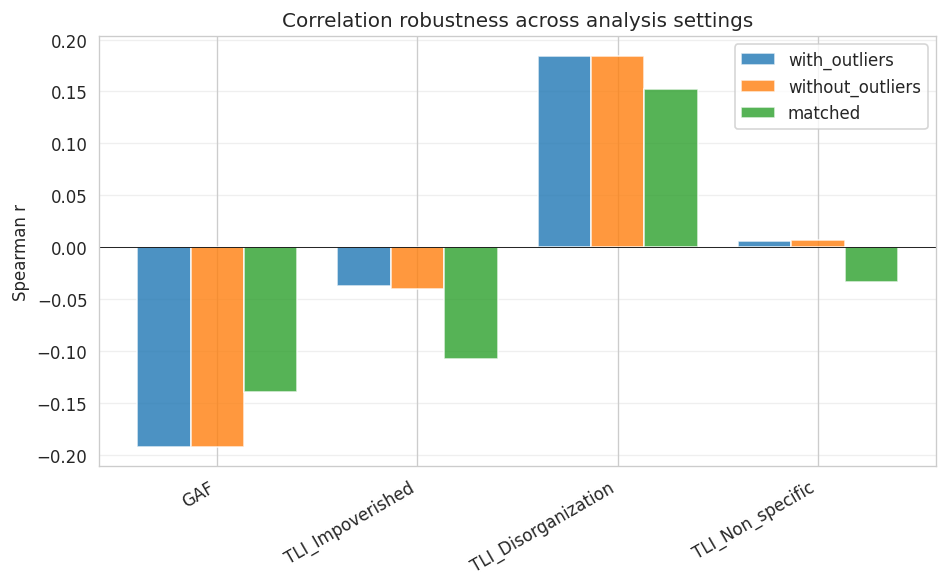

Saved: figures/divergence/cross_setting/robustness_scatter.png


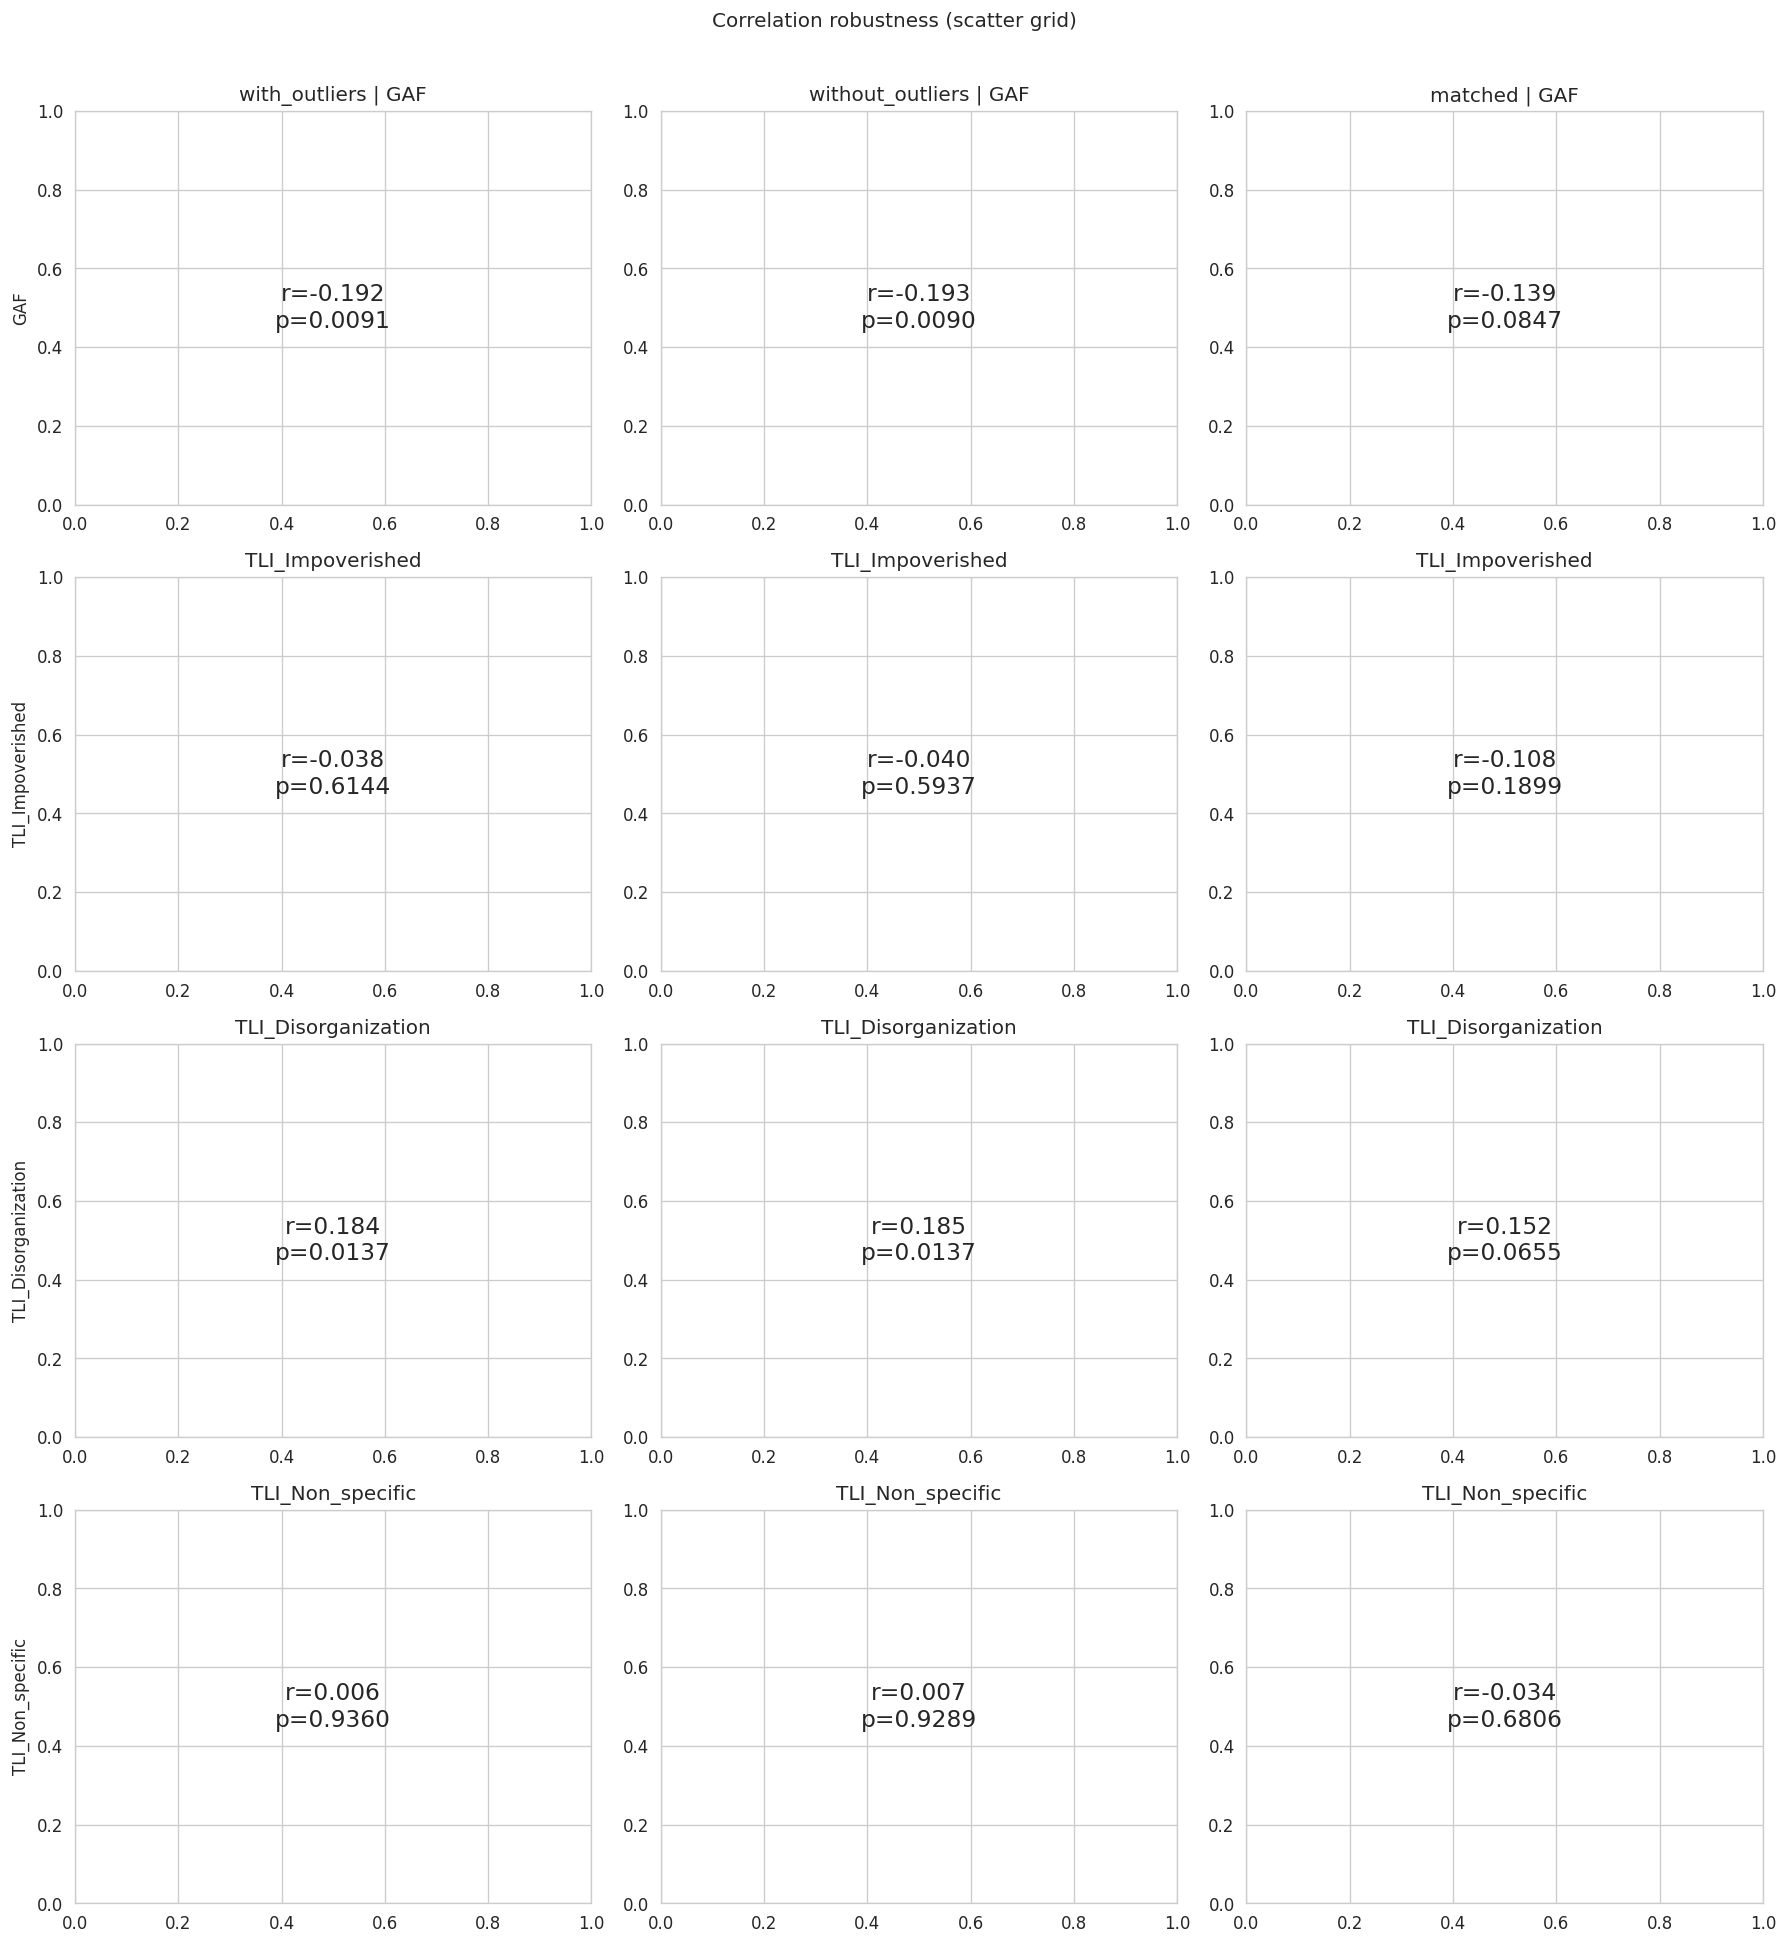

In [ ]:
plot_cross_setting(all_corr_dfs, figure_dir=FIGURE_DIR)

In [ ]:
# Summary table of all comparisons (raw + deconfounded)
summary_rows = []
for sname, res in all_results.items():
    row_raw = {"Setting": sname, "Analysis": "Raw"}
    row_raw.update(res["comparison"])
    summary_rows.append(row_raw)
    if "deconfounded" in res:
        row_resid = {"Setting": sname, "Analysis": "Residualized"}
        row_resid.update(res["deconfounded"]["comparison_resid"])
        summary_rows.append(row_resid)
summary_df = pd.DataFrame(summary_rows)
summary_df

,Setting,Analysis,Variable,Control (M±SD),Patient (M±SD),Control Median,Patient Median,t,p(t),U,p(MW),Cohens d,r
0,with_outliers,Raw,divergence_div_mean,0.17±0.01,0.17±0.01,0.168737,0.169862,2.033871,0.042689,18447.0,0.089043,0.212739,-0.102861
1,with_outliers,Residualized,divergence_div_mean_resid,-0.00±0.01,0.00±0.01,-0.000519,0.000774,1.684019,0.093075,16598.0,0.168351,0.180135,-0.085227
2,without_outliers,Raw,divergence_div_mean_wins,0.17±0.01,0.17±0.01,0.168737,0.169862,1.784404,0.075191,18446.0,0.089184,0.186645,-0.102801
3,without_outliers,Residualized,divergence_div_mean_wins_resid,-0.00±0.01,0.00±0.01,-0.000613,0.000755,1.380812,0.168223,16535.0,0.189885,0.147702,-0.081108
4,matched,Raw,divergence_div_mean,0.17±0.01,0.17±0.01,0.168342,0.169006,1.385658,0.166841,13193.0,0.280550,0.156394,-0.070469
5,matched,Residualized,divergence_div_mean_resid,-0.00±0.01,0.00±0.01,-0.000512,0.000744,1.453312,0.147142,13247.0,0.251706,0.164030,-0.074851


## 5. Alternative metrics comparison

In [ ]:
alt_metrics = [
    f"{MODEL}_div_median", f"{MODEL}_div_mean",
    f"{MODEL}_div_p90", f"{MODEL}_div_p75",
    f"{MODEL}_div_std", f"{MODEL}_div_cv",
    f"{MODEL}_prop_high_div",
]

# Group comparison for each metric
alt_comp = pd.DataFrame([group_comparison(df, m) for m in alt_metrics if m in df.columns])
alt_comp

,Variable,Control (M±SD),Patient (M±SD),Control Median,Patient Median,t,p(t),U,p(MW),Cohens d,r
0,divergence_div_median,0.17±0.01,0.17±0.01,0.171529,0.172580,1.676686,0.094462,17957.0,0.223973,0.175378,-0.073566
1,divergence_div_mean,0.17±0.01,0.17±0.01,0.168737,0.169862,2.033871,0.042689,18447.0,0.089043,0.212739,-0.102861
2,divergence_div_p90,0.21±0.01,0.21±0.01,0.211198,0.212893,1.985534,0.047835,18394.0,0.099338,0.207683,-0.099692
3,divergence_div_p75,0.19±0.01,0.19±0.01,0.193632,0.194613,1.620908,0.105903,17968.0,0.219857,0.169544,-0.074224
4,divergence_div_std,0.04±0.00,0.04±0.00,0.035339,0.035067,0.180186,0.857107,16425.0,0.766022,0.018847,0.018025
5,divergence_div_cv,0.21±0.02,0.21±0.03,0.209955,0.204571,-0.481699,0.630309,15738.0,0.328678,-0.050385,0.059098
6,divergence_prop_high_div,0.09±0.05,0.10±0.05,0.088235,0.103448,2.093597,0.036987,18899.0,0.031761,0.218986,-0.129884


Saved: figures/divergence/advanced/metrics_heatmap.png


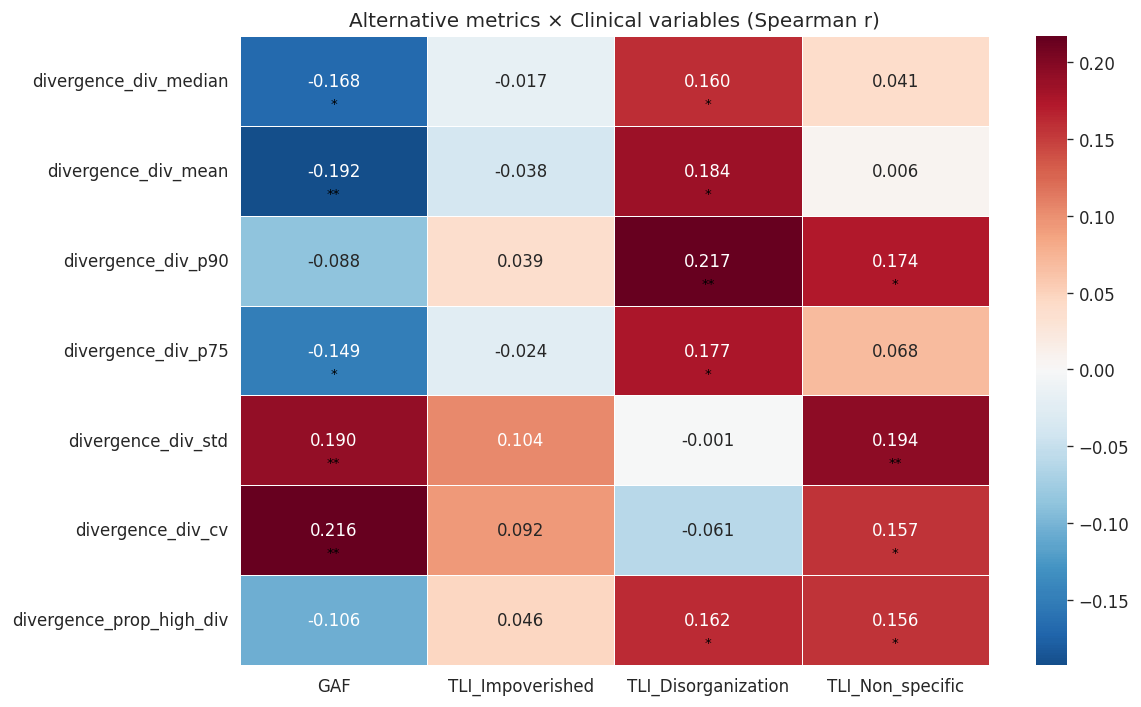

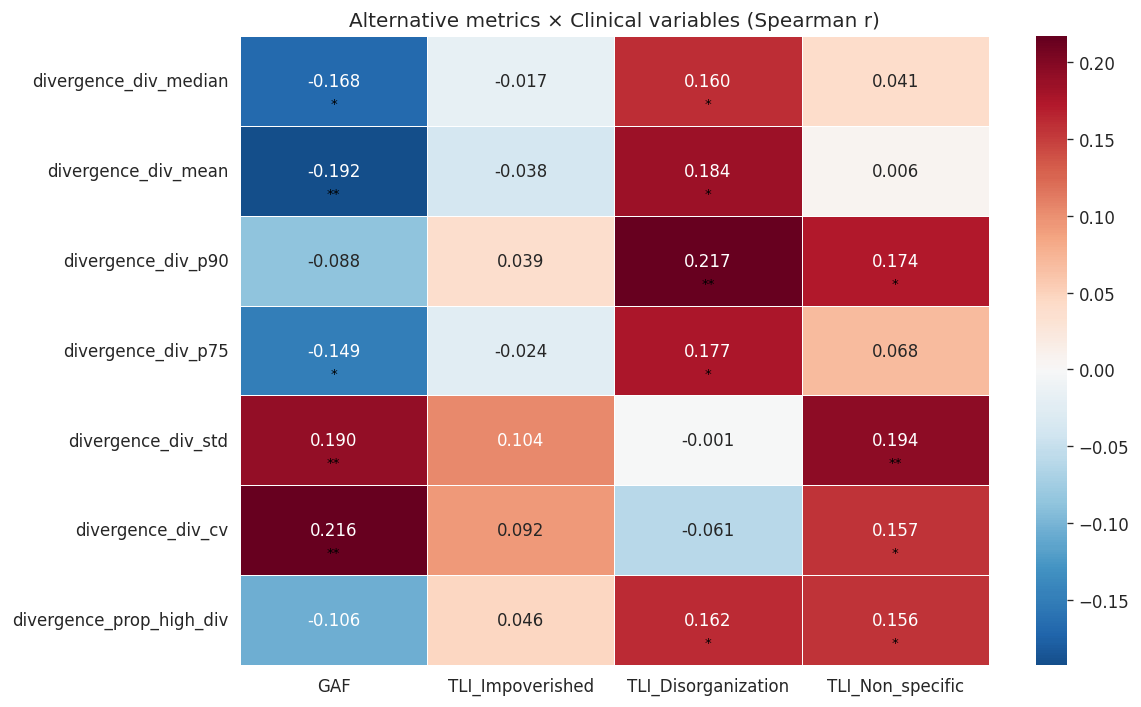

In [ ]:
# Correlation heatmap: metrics × clinical variables
patients = df[df['is_patient'] == 1].copy()
r_matrix = pd.DataFrame(index=[m for m in alt_metrics if m in df.columns], columns=clinical_vars, dtype=float)
p_matrix = r_matrix.copy()

for metric in r_matrix.index:
    for cvar in clinical_vars:
        sub = patients[[metric, cvar]].dropna()
        if len(sub) >= 5:
            r, p = spearmanr(sub[metric], sub[cvar])
            r_matrix.loc[metric, cvar] = r
            p_matrix.loc[metric, cvar] = p

plot_metrics_heatmap(
    r_matrix.astype(float),
    p_matrix.astype(float),
    title="Alternative metrics × Clinical variables (Spearman r)",
    save_path=os.path.join(FIGURE_DIR, "advanced", "metrics_heatmap.png"),
)

## 6. TLI subscale analysis (Steiger's Z)

In [ ]:
tli_metrics = [PPL_VAR, f"{MODEL}_div_p90", f"{MODEL}_prop_high_div"]
tli_vars = ["TLI_Impoverished", "TLI_Disorganization", "TLI_Non_specific"]

for metric in tli_metrics:
    sub = patients[[metric] + tli_vars].dropna()
    if len(sub) < 10:
        continue
    r_imp, _ = spearmanr(sub[metric], sub["TLI_Impoverished"])
    r_dis, _ = spearmanr(sub[metric], sub["TLI_Disorganization"])
    r_id, _ = spearmanr(sub["TLI_Impoverished"], sub["TLI_Disorganization"])
    z, p = steigers_z(r_imp, r_dis, r_id, len(sub))
    print(f"{metric}: r_imp={r_imp:.3f}, r_dis={r_dis:.3f}, Steiger Z={z:.3f}, p={p:.4f}")

divergence_div_mean: r_imp=-0.038, r_dis=0.184, Steiger Z=-1.983, p=0.0474
divergence_div_p90: r_imp=0.039, r_dis=0.217, Steiger Z=-1.594, p=0.1109
divergence_prop_high_div: r_imp=0.046, r_dis=0.162, Steiger Z=-1.031, p=0.3025


## 7. ROC analysis

  GAF < 60 | divergence_div_mean: AUC=0.550
  GAF < 60 | divergence_div_p90: AUC=0.539
  GAF < 60 | divergence_prop_high_div: AUC=0.551
  TLI Disorganization > 0 | divergence_div_mean: AUC=0.636
  TLI Disorganization > 0 | divergence_div_p90: AUC=0.605
  TLI Disorganization > 0 | divergence_prop_high_div: AUC=0.574
  TLI Impoverished > 0 | divergence_div_mean: AUC=0.482
  TLI Impoverished > 0 | divergence_div_p90: AUC=0.506
  TLI Impoverished > 0 | divergence_prop_high_div: AUC=0.513
Saved: figures/divergence/advanced/roc_curves.png


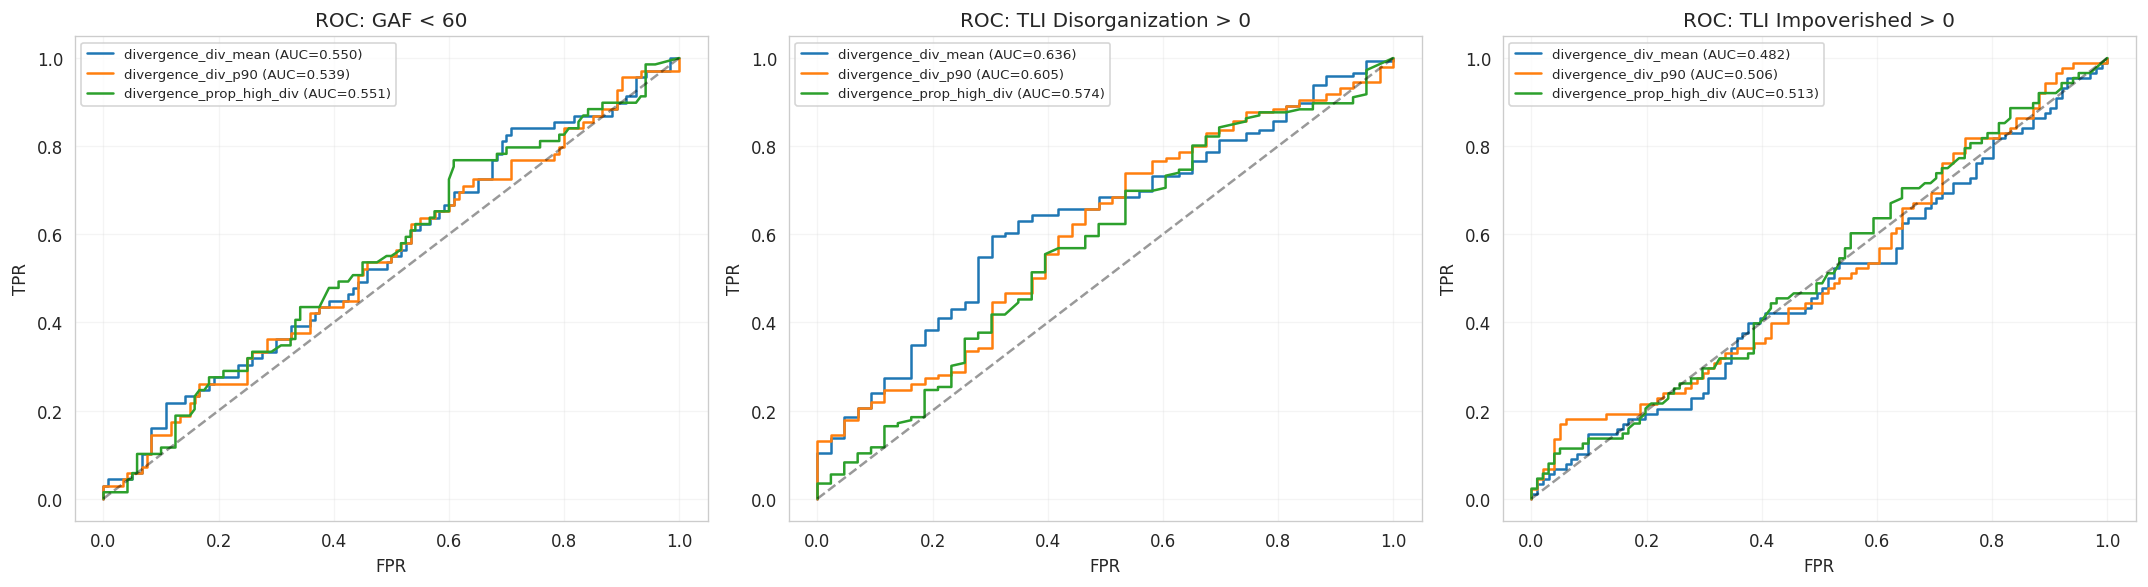

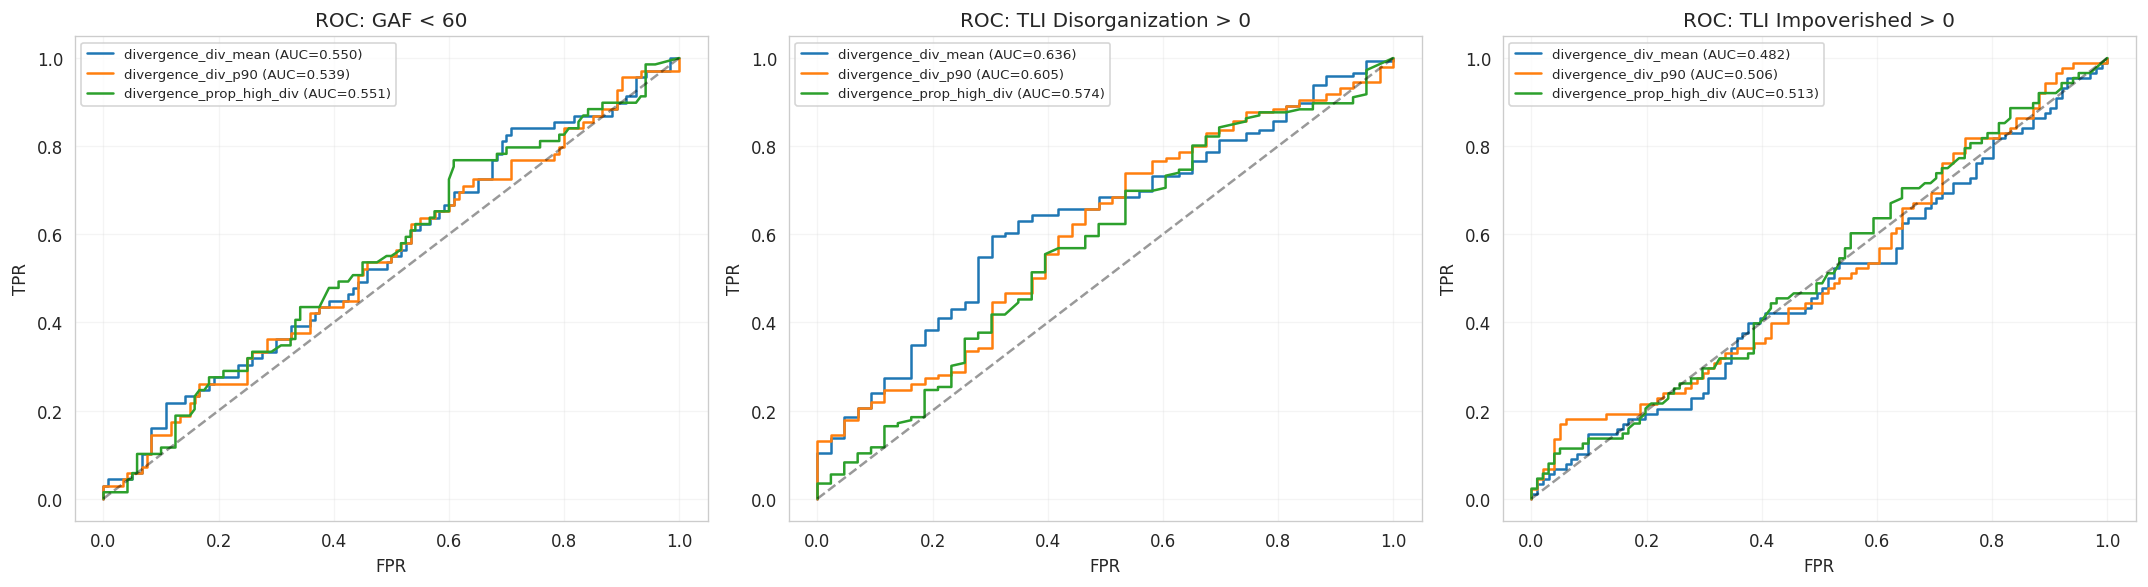

In [ ]:
# Define clinical impairment targets
patients = df[df['is_patient'] == 1].copy()
patients['GAF_impaired'] = (patients['GAF'] < 60).astype(int)
patients['TLI_dis_any'] = (patients['TLI_Disorganization'] > 0).astype(int)
patients['TLI_imp_any'] = (patients['TLI_Impoverished'] > 0).astype(int)

div_roc_metrics = [PPL_VAR, f"{MODEL}_div_p90", f"{MODEL}_prop_high_div"]
roc_targets = {
    'GAF < 60': 'GAF_impaired',
    'TLI Disorganization > 0': 'TLI_dis_any',
    'TLI Impoverished > 0': 'TLI_imp_any',
}

all_rocs = {}
for target_label, target_col in roc_targets.items():
    rocs = compute_roc(patients, div_roc_metrics, target_col)
    all_rocs[target_label] = rocs
    for r in rocs:
        print(f"  {target_label} | {r['metric']}: AUC={r['auc']:.3f}")

plot_roc_curves(
    [],  # not used directly
    all_rocs,
    save_path=os.path.join(FIGURE_DIR, "advanced", "roc_curves.png"),
)

In [ ]:
# Combined metric: logistic regression CV
features_combined = [PPL_VAR, f"{MODEL}_div_std", f"{MODEL}_prop_high_div"]
for target_label, target_col in roc_targets.items():
    auc_combined = logistic_cv_auc(patients, features_combined, target_col)
    auc_singles = {m: logistic_cv_auc(patients, [m], target_col) for m in features_combined}
    print(f"{target_label}: combined AUC={auc_combined:.3f}")
    for m, a in auc_singles.items():
        print(f"  single {m}: AUC={a:.3f}")

GAF < 60: combined AUC=0.551
  single divergence_div_mean: AUC=0.546
  single divergence_div_std: AUC=0.576
  single divergence_prop_high_div: AUC=0.551
TLI Disorganization > 0: combined AUC=0.584
  single divergence_div_mean: AUC=0.640
  single divergence_div_std: AUC=0.556
  single divergence_prop_high_div: AUC=0.581
TLI Impoverished > 0: combined AUC=0.421
  single divergence_div_mean: AUC=0.439
  single divergence_div_std: AUC=0.542
  single divergence_prop_high_div: AUC=0.420


## 8. Confounder analysis

Saved: figures/divergence/advanced/confounder_analysis.png


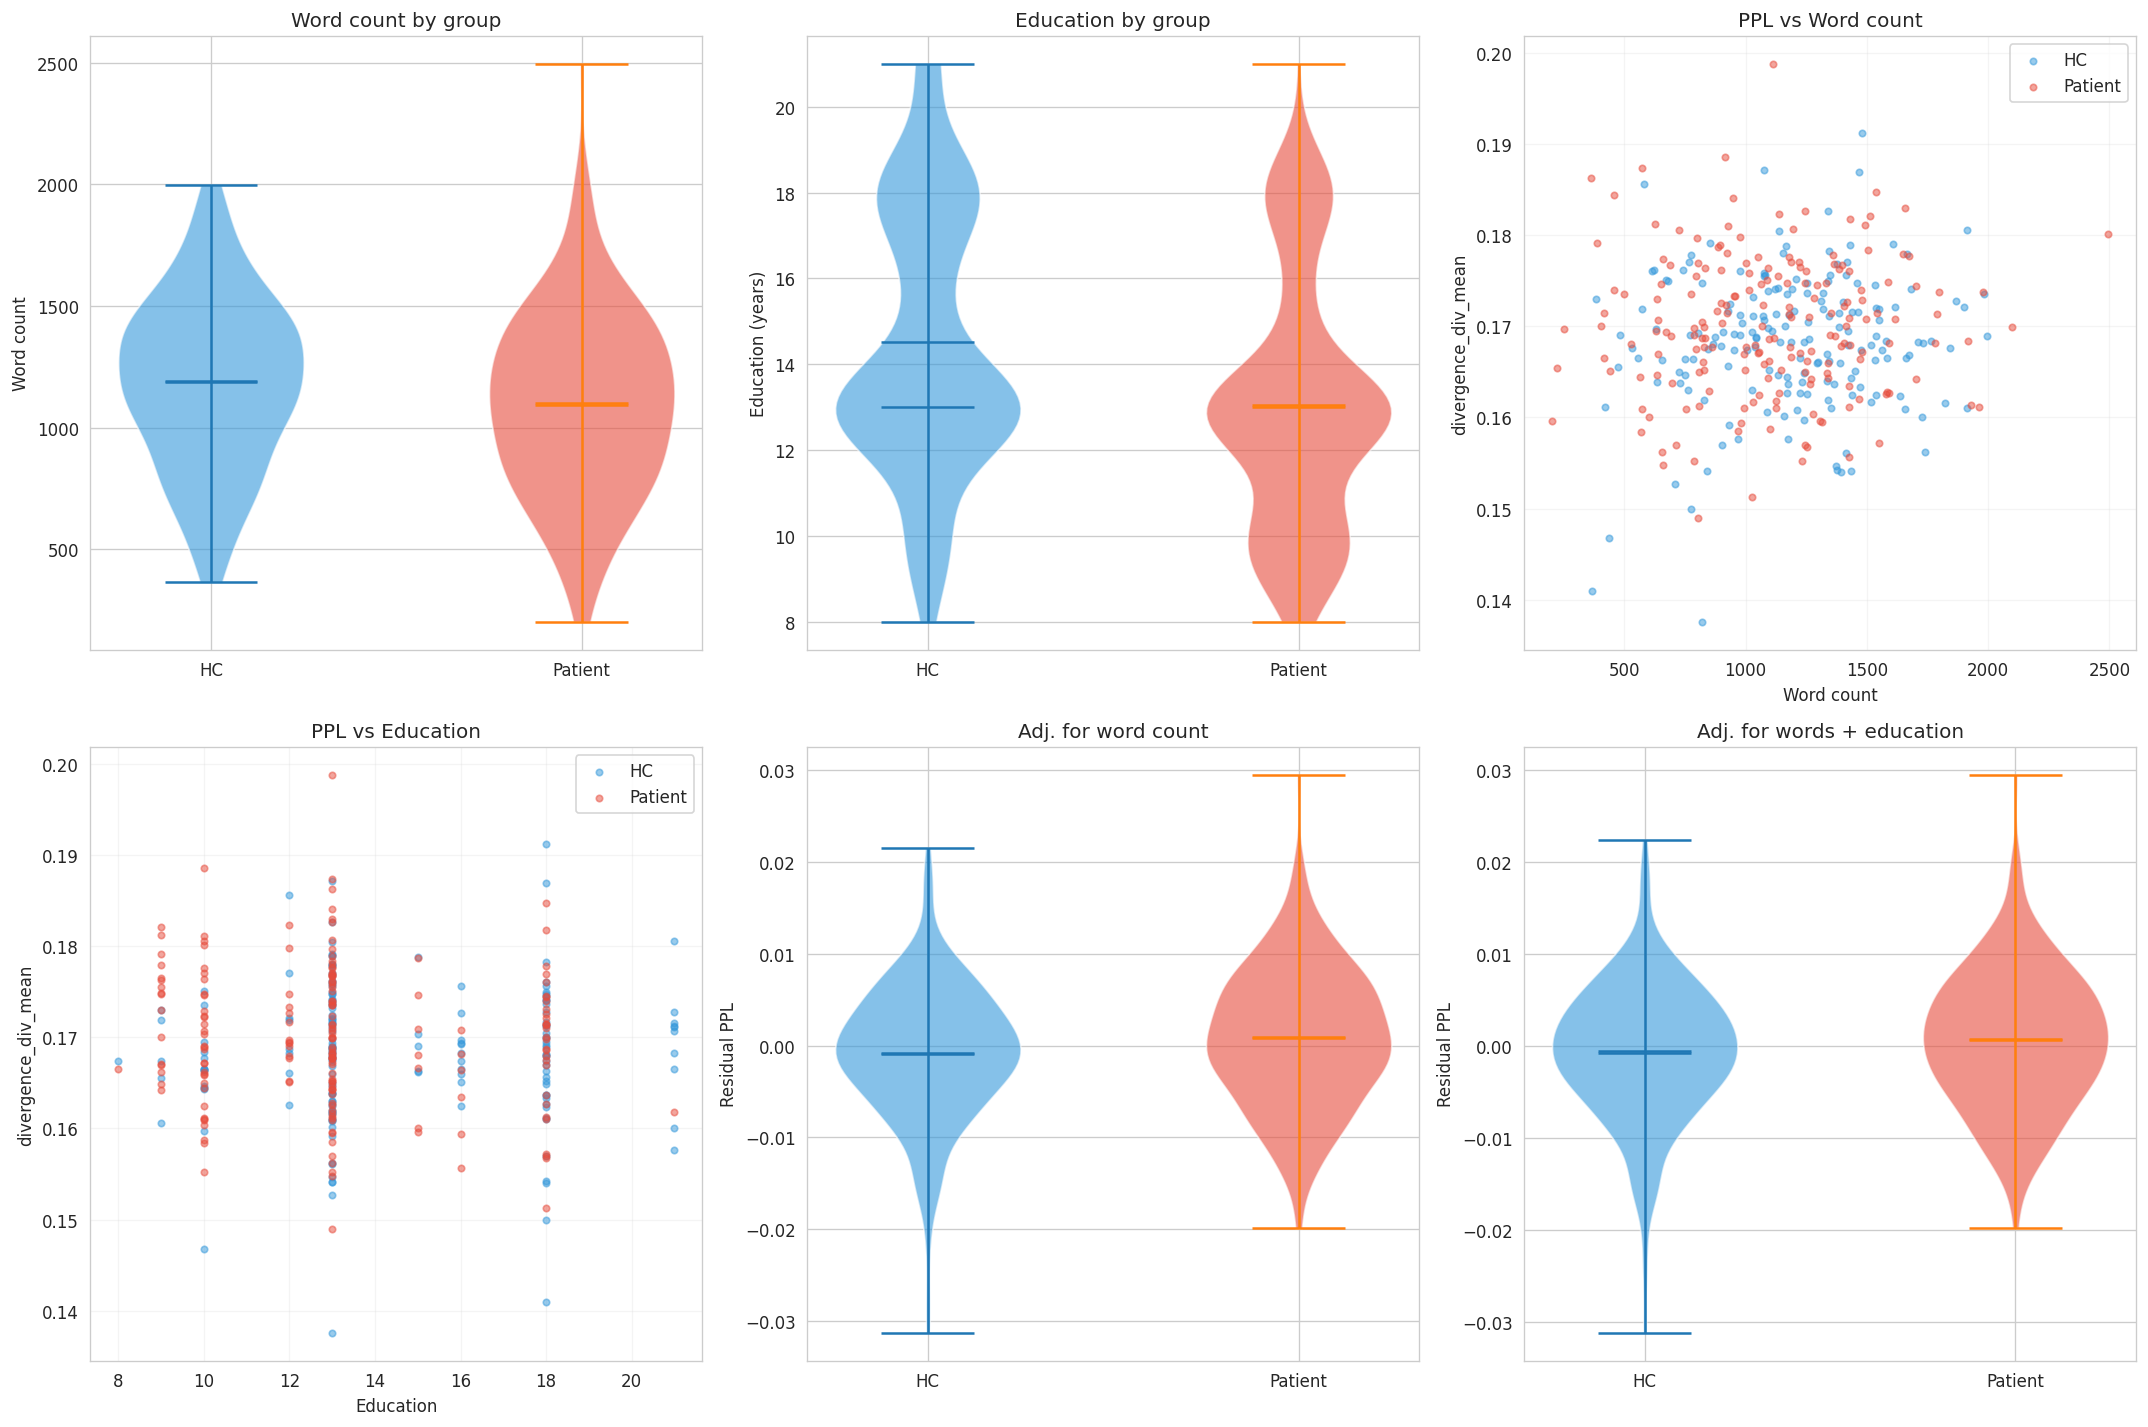

Saved: figures/divergence/advanced/raw_vs_residualized.png


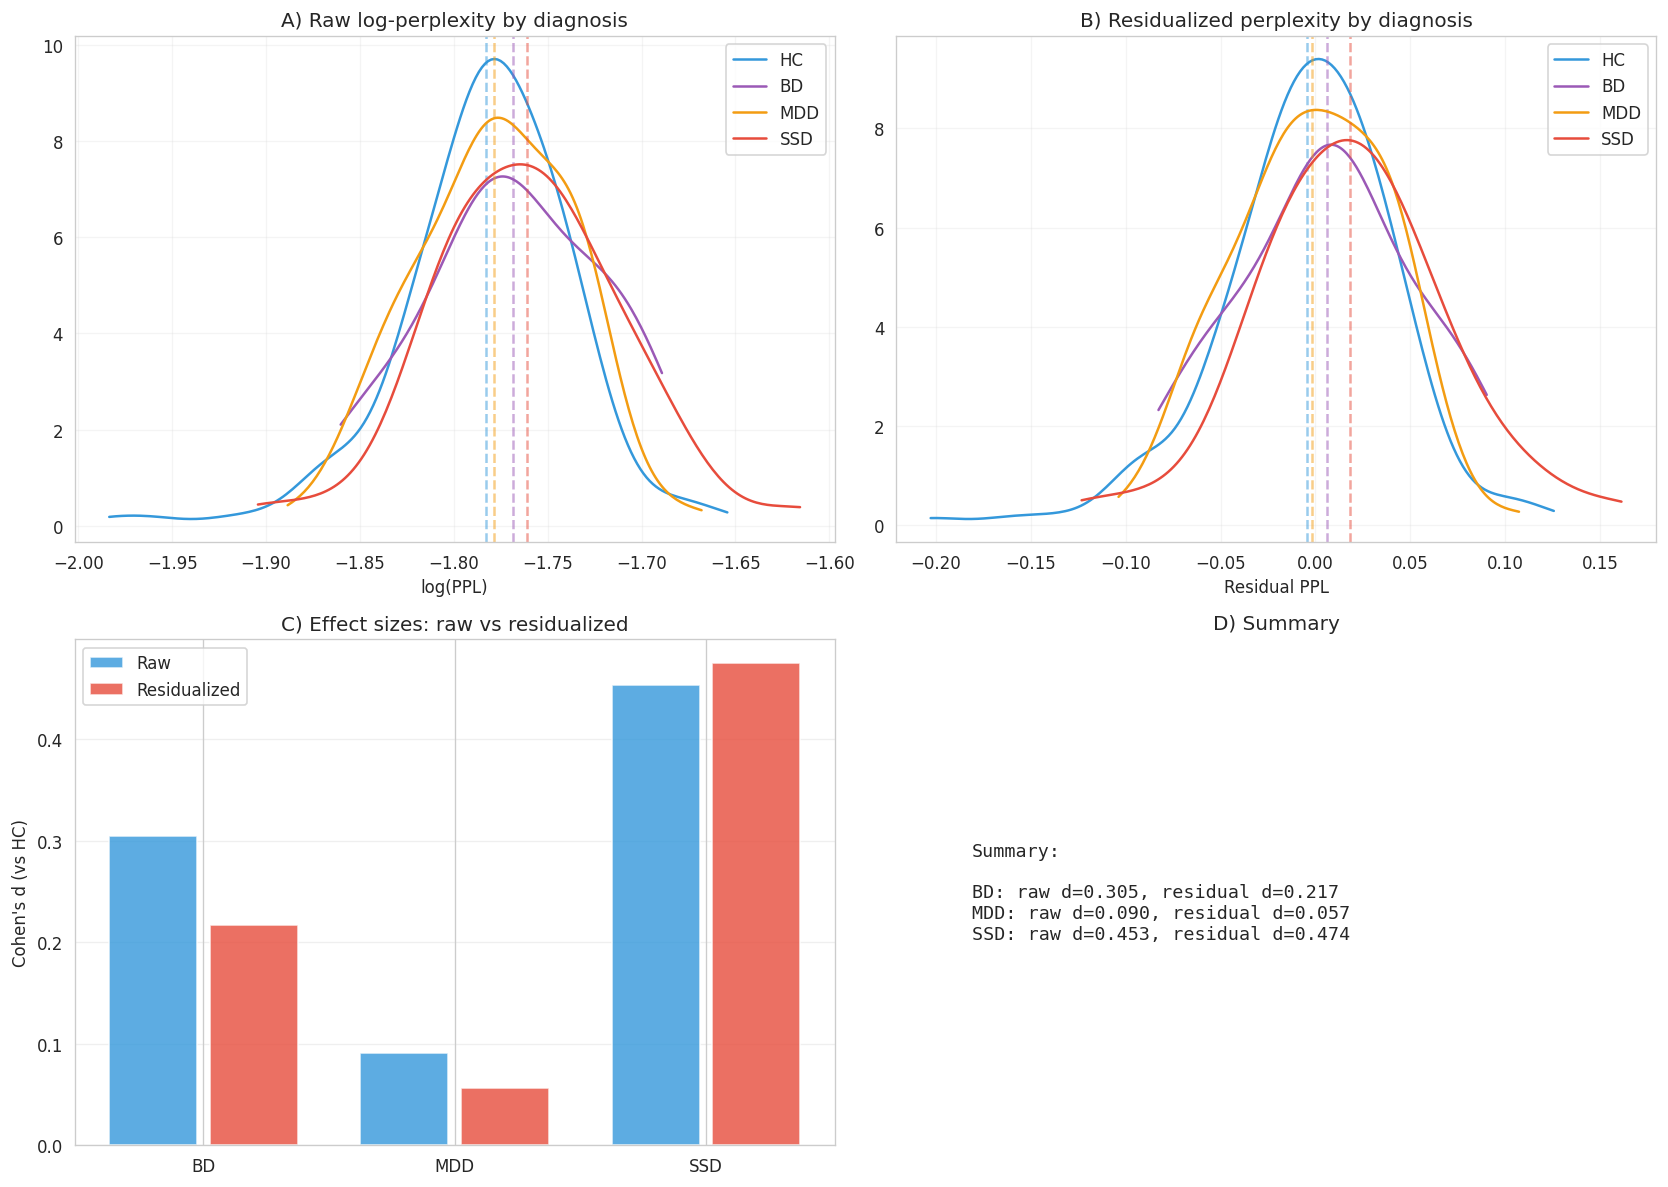

Saved: figures/divergence/advanced/raw_perplexity_basic.png


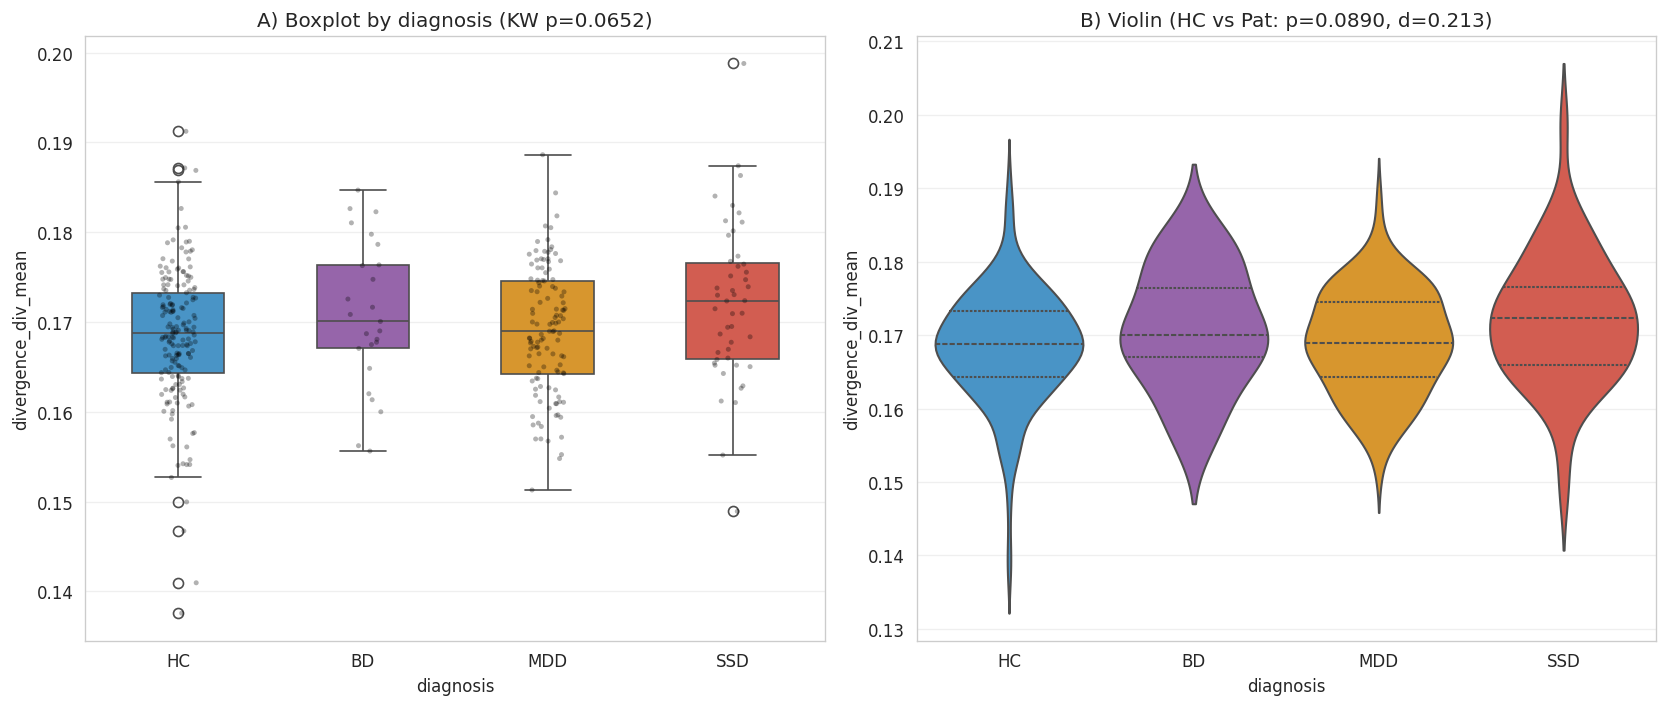

In [ ]:
# Confounder visualisation
plot_advanced(
    df=df,
    patients=patients,
    ppl_var=PPL_VAR,
    wc_var=WC_VAR,
    figure_dir=FIGURE_DIR,
)

### 8b. Deconfounding: residualize PPL, then re-run group comparisons & clinical correlations

Instead of nested ANOVA (where confounders absorb the group signal), we regress out
confounders (log word count + education) from perplexity and then test the **residualized**
perplexity for group differences and clinical associations.

In [ ]:
# ── Residualize perplexity ────────────────────────────────────────
# Regress out log(word_count) + education from PPL, keep the residuals.
import statsmodels.api as sm

df_deconf = df.copy()
df_deconf["log_words"] = np.log1p(df_deconf[WC_VAR])

confounders = ["log_words"]
if "education" in df_deconf.columns:
    confounders.append("education")

df_deconf[f"{PPL_VAR}_resid"] = np.nan
resid = residualize_ppl(df_deconf, PPL_VAR, confounders)
df_deconf.loc[resid.index, f"{PPL_VAR}_resid"] = resid

RESID_VAR = f"{PPL_VAR}_resid"
print(f"Confounders removed: {confounders}")
print(f"Residualized variable: {RESID_VAR}")
print(f"N with residuals: {df_deconf[RESID_VAR].notna().sum()}")

# ── Group comparison: raw vs residualized ────────────────────────
print("\n" + "=" * 60)
print("GROUP COMPARISON — Raw PPL")
print("=" * 60)
comp_raw = group_comparison(df_deconf, PPL_VAR)
for k, v in comp_raw.items():
    print(f"  {k}: {v}")

print("\n" + "=" * 60)
print("GROUP COMPARISON — Residualized PPL")
print("=" * 60)
comp_resid = group_comparison(df_deconf.dropna(subset=[RESID_VAR]), RESID_VAR)
for k, v in comp_resid.items():
    print(f"  {k}: {v}")

# Summary table
comp_summary = pd.DataFrame([
    {"Metric": "Raw PPL", **{k: v for k, v in comp_raw.items() if k != "Variable"}},
    {"Metric": "Residualized PPL", **{k: v for k, v in comp_resid.items() if k != "Variable"}},
])
comp_summary

Confounders removed: ['log_words', 'education']
Residualized variable: divergence_div_mean_resid
N with residuals: 350

GROUP COMPARISON — Raw PPL
  Variable: divergence_div_mean
  Control (M±SD): 0.17±0.01
  Patient (M±SD): 0.17±0.01
  Control Median: 0.1687369483548241
  Patient Median: 0.16986176888147986
  t: 2.0338707233170923
  p(t): 0.04268937191522844
  U: 18447.0
  p(MW): 0.08904290196815882
  Cohens d: 0.2127386271487847
  r: -0.10286072997937401

GROUP COMPARISON — Residualized PPL
  Variable: divergence_div_mean_resid
  Control (M±SD): -0.00±0.01
  Patient (M±SD): 0.00±0.01
  Control Median: -0.0005189174323047829
  Patient Median: 0.000774146173689011
  t: 1.684018802094445
  p(t): 0.09307470972239305
  U: 16598.0
  p(MW): 0.16835062654862298
  Cohens d: 0.18013508903096848
  r: -0.08522671548595895


,Metric,Control (M±SD),Patient (M±SD),Control Median,Patient Median,t,p(t),U,p(MW),Cohens d,r
0,Raw PPL,0.17±0.01,0.17±0.01,0.168737,0.169862,2.033871,0.042689,18447.0,0.089043,0.212739,-0.102861
1,Residualized PPL,-0.00±0.01,0.00±0.01,-0.000519,0.000774,1.684019,0.093075,16598.0,0.168351,0.180135,-0.085227


In [ ]:
# ── Clinical correlations: raw vs residualized ───────────────────
patients_deconf = df_deconf[df_deconf["is_patient"] == 1].copy()

print("CLINICAL CORRELATIONS — Raw PPL (patients only)")
corr_raw = clinical_correlations(patients_deconf, PPL_VAR, clinical_vars)
print(corr_raw.to_string(index=False))

print("\nCLINICAL CORRELATIONS — Residualized PPL (patients only)")
corr_resid = clinical_correlations(
    patients_deconf.dropna(subset=[RESID_VAR]), RESID_VAR, clinical_vars
)
print(corr_resid.to_string(index=False))

# Side-by-side comparison
merged_corr = corr_raw.merge(
    corr_resid, on="Clinical Variable", suffixes=("_raw", "_resid")
)
merged_corr

CLINICAL CORRELATIONS — Raw PPL (patients only)
  Clinical Variable         r        p   n
                GAF -0.192409 0.009069 183
   TLI_Impoverished -0.038013 0.614424 178
TLI_Disorganization  0.184477 0.013698 178
   TLI_Non_specific  0.006057 0.936045 178

CLINICAL CORRELATIONS — Residualized PPL (patients only)
  Clinical Variable         r        p   n
                GAF -0.183426 0.014818 176
   TLI_Impoverished -0.006547 0.932473 170
TLI_Disorganization  0.129800 0.091596 170
   TLI_Non_specific -0.017734 0.818452 170


,Clinical Variable,r_raw,p_raw,n_raw,r_resid,p_resid,n_resid
0,GAF,-0.192409,0.009069,183,-0.183426,0.014818,176
1,TLI_Impoverished,-0.038013,0.614424,178,-0.006547,0.932473,170
2,TLI_Disorganization,0.184477,0.013698,178,0.129800,0.091596,170
3,TLI_Non_specific,0.006057,0.936045,178,-0.017734,0.818452,170


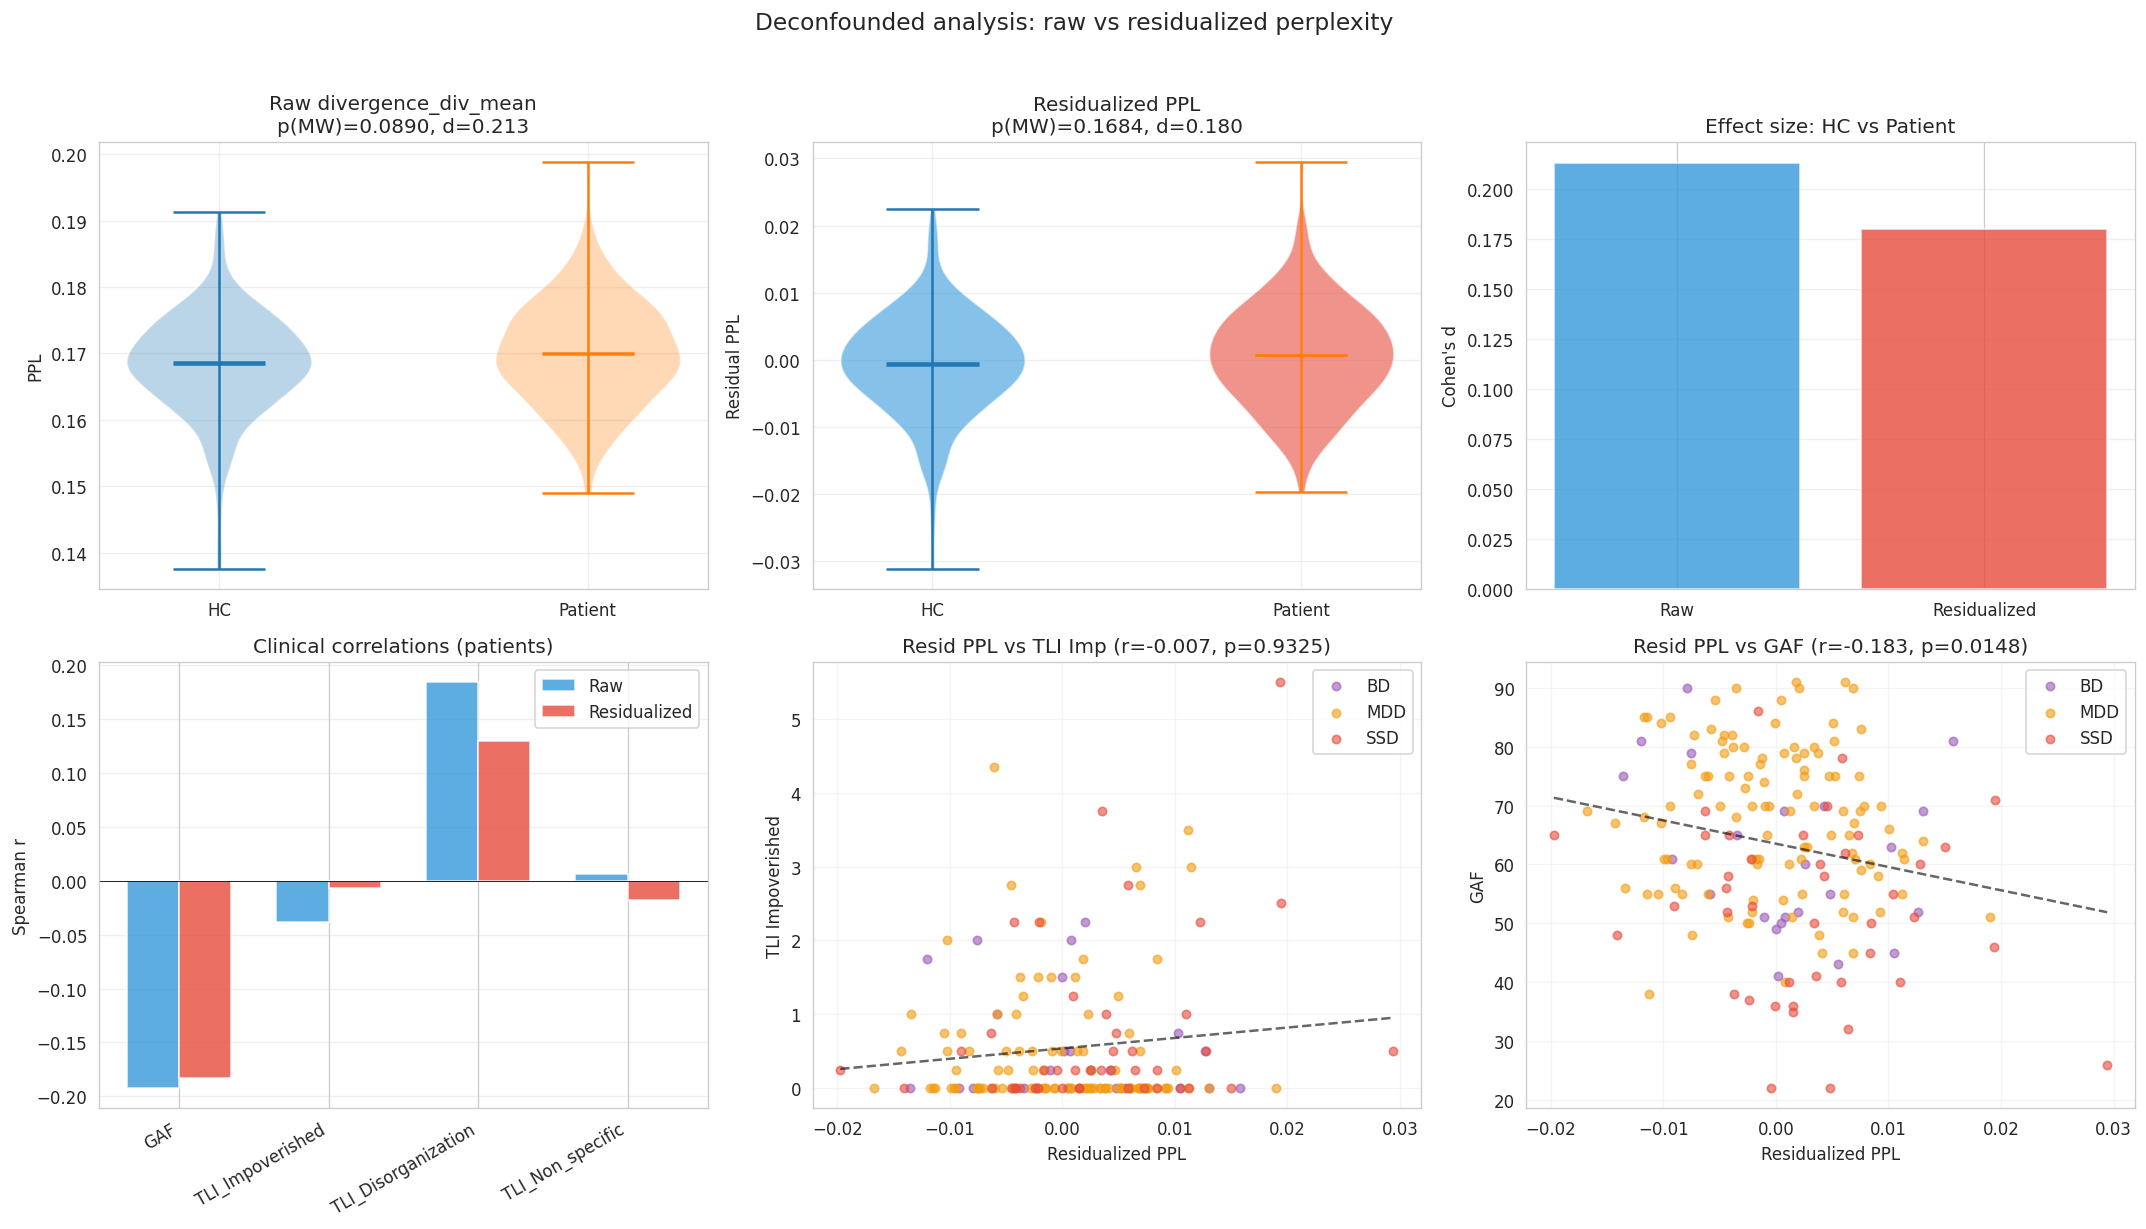

In [ ]:
# ── Visualisation: raw vs residualized ────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Row 1: Raw PPL
ax = axes[0, 0]
for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
    vals = df_deconf[df_deconf["is_patient"] == is_pat][PPL_VAR].dropna()
    ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
ax.set_title(f"Raw {PPL_VAR}\np(MW)={comp_raw['p(MW)']:.4f}, d={comp_raw['Cohens d']:.3f}")
ax.set_ylabel("PPL"); ax.grid(alpha=0.3)

# Row 1: Residualized PPL
ax = axes[0, 1]
for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
    vals = df_deconf[df_deconf["is_patient"] == is_pat][RESID_VAR].dropna()
    parts = ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
    for pc in parts["bodies"]:
        pc.set_facecolor(clr); pc.set_alpha(0.6)
ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
ax.set_title(f"Residualized PPL\np(MW)={comp_resid['p(MW)']:.4f}, d={comp_resid['Cohens d']:.3f}")
ax.set_ylabel("Residual PPL"); ax.grid(alpha=0.3)

# Row 1: Cohen's d comparison
ax = axes[0, 2]
ax.bar(["Raw", "Residualized"], [comp_raw["Cohens d"], comp_resid["Cohens d"]],
       color=["#3498DB", "#E74C3C"], alpha=0.8)
ax.set_ylabel("Cohen's d"); ax.set_title("Effect size: HC vs Patient")
ax.grid(axis="y", alpha=0.3); ax.axhline(0, color="black", lw=0.5)

# Row 2: Clinical correlations comparison
ax = axes[1, 0]
x = np.arange(len(clinical_vars))
w = 0.35
bars_raw = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_raw"]
bars_res = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_resid"]
ax.bar(x - w/2, bars_raw, w, label="Raw", color="#3498DB", alpha=0.8)
ax.bar(x + w/2, bars_res, w, label="Residualized", color="#E74C3C", alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels(clinical_vars, rotation=30, ha="right")
ax.set_ylabel("Spearman r"); ax.set_title("Clinical correlations (patients)")
ax.legend(); ax.axhline(0, color="black", lw=0.5); ax.grid(axis="y", alpha=0.3)

# Row 2: Scatter — residualized PPL vs TLI Impoverished
ax = axes[1, 1]
sub = patients_deconf[[RESID_VAR, "TLI_Impoverished", "diagnosis"]].dropna()
if len(sub) >= 5:
    from functions.plotting.plots import DIAG_ORDER, DIAG_COLORS
    diags = [d for d in DIAG_ORDER if d in sub["diagnosis"].values]
    for dx in diags:
        s = sub[sub["diagnosis"] == dx]
        ax.scatter(s[RESID_VAR], s["TLI_Impoverished"], color=DIAG_COLORS.get(dx, "#888"),
                   label=dx, alpha=0.6, s=25)
    r, p = spearmanr(sub[RESID_VAR], sub["TLI_Impoverished"])
    z = np.polyfit(sub[RESID_VAR], sub["TLI_Impoverished"], 1)
    xs = np.linspace(sub[RESID_VAR].min(), sub[RESID_VAR].max(), 100)
    ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
    ax.set_xlabel("Residualized PPL"); ax.set_ylabel("TLI Impoverished")
    ax.set_title(f"Resid PPL vs TLI Imp (r={r:.3f}, p={p:.4f})")
    ax.legend(); ax.grid(alpha=0.2)

# Row 2: Scatter — residualized PPL vs GAF
ax = axes[1, 2]
sub = patients_deconf[[RESID_VAR, "GAF", "diagnosis"]].dropna()
if len(sub) >= 5:
    for dx in diags:
        s = sub[sub["diagnosis"] == dx]
        ax.scatter(s[RESID_VAR], s["GAF"], color=DIAG_COLORS.get(dx, "#888"),
                   label=dx, alpha=0.6, s=25)
    r, p = spearmanr(sub[RESID_VAR], sub["GAF"])
    z = np.polyfit(sub[RESID_VAR], sub["GAF"], 1)
    xs = np.linspace(sub[RESID_VAR].min(), sub[RESID_VAR].max(), 100)
    ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
    ax.set_xlabel("Residualized PPL"); ax.set_ylabel("GAF")
    ax.set_title(f"Resid PPL vs GAF (r={r:.3f}, p={p:.4f})")
    ax.legend(); ax.grid(alpha=0.2)

fig.suptitle("Deconfounded analysis: raw vs residualized perplexity", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "advanced", "deconfounded_analysis.png"),
            dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# ── Per-diagnosis deconfounded comparison vs HC ──────────────────
from functions.analysis.statistics import pairwise_vs_hc, kruskal_wallis_test

print("PAIRWISE vs HC — Raw PPL")
pw_raw = pairwise_vs_hc(df_deconf, PPL_VAR)
print(pd.DataFrame(pw_raw).to_string(index=False))

print("\nPAIRWISE vs HC — Residualized PPL")
pw_resid = pairwise_vs_hc(df_deconf.dropna(subset=[RESID_VAR]), RESID_VAR)
print(pd.DataFrame(pw_resid).to_string(index=False))

print("\nKruskal-Wallis across diagnoses:")
kw_raw_stat, kw_raw_p = kruskal_wallis_test(df_deconf, PPL_VAR)
kw_res_stat, kw_res_p = kruskal_wallis_test(
    df_deconf.dropna(subset=[RESID_VAR]), RESID_VAR
)
print(f"  Raw:          H={kw_raw_stat:.3f}, p={kw_raw_p:.4f}")
print(f"  Residualized: H={kw_res_stat:.3f}, p={kw_res_p:.4f}")

PAIRWISE vs HC — Raw PPL
Diagnosis       U        p  Cohen's d   n
       BD  2568.0 0.194452   0.312522  25
      MDD 10734.0 0.595296   0.087422 117
      SSD  5145.0 0.012631   0.466755  47

PAIRWISE vs HC — Residualized PPL
Diagnosis      U        p  Cohen's d   n
       BD 2166.0 0.374602   0.221045  23
      MDD 9897.0 0.792189   0.052134 115
      SSD 4535.0 0.012118   0.487304  43

Kruskal-Wallis across diagnoses:
  Raw:          H=7.222, p=0.0652
  Residualized: H=6.947, p=0.0736


## 9. Summary

In [ ]:
print("Analysis complete.")
print(f"Figures saved to: {os.path.abspath(FIGURE_DIR)}")

Analysis complete.
Figures saved to: /zi/home/esra.lenz/Documents/00_HITKIP/11_normative/mnm_ppl/figures/divergence
